In [1]:

# ============================================================
# MODEL 1: LINEAR REGRESSION — MATHEMATICS ONLY
# G1 and G2 excluded
# 80% training / 20% testing
# Output: actual and predicted G3 for test students only
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Locate the project directory
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found at:\n{DATA_FILE}\n"
        "Check the project folder and notebook working directory."
    )

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load mathematics data only
# ------------------------------------------------------------

df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

# Target: final mathematics grade
target_column = "G3_math"

if target_column not in df.columns:
    raise ValueError(
        f"Target column '{target_column}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Remove target-related columns and metadata from the features.
# G1 and G2 are deliberately excluded in this experiment.
excluded_columns = [
    "G1",
    "G2",
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject",
]

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

X = df[feature_columns].copy()
y = df[target_column].copy()

# Ensure the features are numeric and handle any missing values
# without learning imputation values from the test set.
X = X.apply(pd.to_numeric, errors="raise")

if X.isna().any().any() or y.isna().any():
    raise ValueError(
        "Missing values were found. Please inspect the dataset "
        "before fitting this first model."
    )

print("Dataset: Mathematics")
print(f"Number of students: {len(df)}")
print(f"Number of input features: {X.shape[1]}")
print("G1 included: No")
print("G2 included: No")


# ------------------------------------------------------------
# 3. Create a reproducible 80/20 train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"\nTraining students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# ------------------------------------------------------------
# 4. Train Linear Regression
# ------------------------------------------------------------

model = LinearRegression()
model.fit(X_train, y_train)

# Predict only for the held-out test students
y_pred = model.predict(X_test)


# ------------------------------------------------------------
# 5. Evaluate the model
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== LINEAR REGRESSION RESULTS ==========")
print(f"Test MAE : {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²  : {r2:.4f}")


# ------------------------------------------------------------
# 6. Save only actual G3 and predicted G3 to Excel
# ------------------------------------------------------------

output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_file = RESULTS_DIR / "Linear_Regression_Mat.xlsx"

output_df.to_excel(
    output_file,
    index=False,
    sheet_name="Mathematics"
)

print(f"\nPredictions saved to:\n{output_file}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Number of students: 395
Number of input features: 56
G1 included: No
G2 included: No

Training students: 316
Testing students: 79

========== LINEAR REGRESSION RESULTS ==========
Test MAE : 3.3953
Test RMSE: 4.1957
Test R²  : 0.1415

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/Linear_Regression_Mat.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


/Users/jaskirat_singh_grewal/Documents/IDC409_Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [8]:

# ============================================================
# MODEL 1: LINEAR REGRESSION — MATHEMATICS ONLY
# G1 and G2 excluded
# 80% training / 20% testing
# Output: actual and predicted G3 for test students only
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Locate the project directory
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found at:\n{DATA_FILE}\n"
        "Check the project folder and notebook working directory."
    )

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load mathematics data only
# ------------------------------------------------------------

df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

# Target: final mathematics grade
target_column = "G3_math"

if target_column not in df.columns:
    raise ValueError(
        f"Target column '{target_column}' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Remove target-related columns and metadata from the features.
# G1 and G2 are deliberately excluded in this experiment.
excluded_columns = [
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject",
]

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

X = df[feature_columns].copy()
y = df[target_column].copy()

# Ensure the features are numeric and handle any missing values
# without learning imputation values from the test set.
X = X.apply(pd.to_numeric, errors="raise")

if X.isna().any().any() or y.isna().any():
    raise ValueError(
        "Missing values were found. Please inspect the dataset "
        "before fitting this first model."
    )

print("Dataset: Mathematics")
print(f"Number of students: {len(df)}")
print(f"Number of input features: {X.shape[1]}")
print("G1 included: No")
print("G2 included: No")


# ------------------------------------------------------------
# 3. Create a reproducible 80/20 train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"\nTraining students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# ------------------------------------------------------------
# 4. Train Linear Regression
# ------------------------------------------------------------

model = LinearRegression()
model.fit(X_train, y_train)

# Predict only for the held-out test students
y_pred = model.predict(X_test)


# ------------------------------------------------------------
# 5. Evaluate the model
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== LINEAR REGRESSION RESULTS ==========")
print(f"Test MAE : {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²  : {r2:.4f}")


# ------------------------------------------------------------
# 6. Save only actual G3 and predicted G3 to Excel
# ------------------------------------------------------------

output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_file = RESULTS_DIR / "Linear_Regression_Mat_g1g2.xlsx"

output_df.to_excel(
    output_file,
    index=False,
    sheet_name="Mathematics"
)

print(f"\nPredictions saved to:\n{output_file}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Number of students: 395
Number of input features: 58
G1 included: No
G2 included: No

Training students: 316
Testing students: 79

========== LINEAR REGRESSION RESULTS ==========
Test MAE : 1.6467
Test RMSE: 2.3784
Test R²  : 0.7241

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/Linear_Regression_Mat_g1g2.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [2]:

# ============================================================
# MODEL 2: RIDGE REGRESSION — MATHEMATICS ONLY
# G1 and G2 excluded
# 80% training / 20% testing
# Output: actual and predicted G3 for test students only
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Locate the project directory
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found at:\n{DATA_FILE}\n"
        "Check the project folder and notebook working directory."
    )

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load mathematics data only
# ------------------------------------------------------------

df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_column = "G3_math"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' was not found.")

# Exclude previous grades and all target/metadata columns
excluded_columns = [
    "G1",
    "G2",
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject",
]

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

X = df[feature_columns].copy().apply(pd.to_numeric, errors="raise")
y = df[target_column].copy()

if X.isna().any().any() or y.isna().any():
    raise ValueError(
        "Missing values were found. Inspect the dataset before training."
    )

print("Dataset: Mathematics")
print(f"Number of students: {len(df)}")
print(f"Number of input features: {X.shape[1]}")
print("G1 included: No")
print("G2 included: No")


# ------------------------------------------------------------
# 3. Same reproducible 80/20 split as Linear Regression
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"\nTraining students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# ------------------------------------------------------------
# 4. Build Ridge pipeline
# Scaling is fitted separately inside each CV training fold.
# ------------------------------------------------------------

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

param_grid = {
    "ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

search.fit(X_train, y_train)

model = search.best_estimator_
y_pred = model.predict(X_test)


# ------------------------------------------------------------
# 5. Evaluate the model
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== RIDGE REGRESSION RESULTS ==========")
print(f"Best alpha: {search.best_params_['ridge__alpha']}")
print(f"Best CV RMSE: {-search.best_score_:.4f}")
print(f"Test MAE : {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²  : {r2:.4f}")


# ------------------------------------------------------------
# 6. Save only actual G3 and predicted G3 to Excel
# ------------------------------------------------------------

output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_file = RESULTS_DIR / "Ridge_Regression_Mat.xlsx"

output_df.to_excel(
    output_file,
    index=False,
    sheet_name="Mathematics"
)

print(f"\nPredictions saved to:\n{output_file}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Number of students: 395
Number of input features: 56
G1 included: No
G2 included: No

Training students: 316
Testing students: 79

========== RIDGE REGRESSION RESULTS ==========
Best alpha: 1000
Best CV RMSE: 4.3574
Test MAE : 3.4424
Test RMSE: 4.2656
Test R²  : 0.1126

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/Ridge_Regression_Mat.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


/Users/jaskirat_singh_grewal/Documents/IDC409_Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/jaskirat_singh_grewal/Doc

In [9]:

# ============================================================
# MODEL 2: RIDGE REGRESSION — MATHEMATICS ONLY
# G1 and G2 excluded
# 80% training / 20% testing
# Output: actual and predicted G3 for test students only
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Locate the project directory
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found at:\n{DATA_FILE}\n"
        "Check the project folder and notebook working directory."
    )

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load mathematics data only
# ------------------------------------------------------------

df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_column = "G3_math"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' was not found.")

# Exclude previous grades and all target/metadata columns
excluded_columns = [
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject",
]

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

X = df[feature_columns].copy().apply(pd.to_numeric, errors="raise")
y = df[target_column].copy()

if X.isna().any().any() or y.isna().any():
    raise ValueError(
        "Missing values were found. Inspect the dataset before training."
    )

print("Dataset: Mathematics")
print(f"Number of students: {len(df)}")
print(f"Number of input features: {X.shape[1]}")
print("G1 included: No")
print("G2 included: No")


# ------------------------------------------------------------
# 3. Same reproducible 80/20 split as Linear Regression
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"\nTraining students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# ------------------------------------------------------------
# 4. Build Ridge pipeline
# Scaling is fitted separately inside each CV training fold.
# ------------------------------------------------------------

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

param_grid = {
    "ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

search.fit(X_train, y_train)

model = search.best_estimator_
y_pred = model.predict(X_test)


# ------------------------------------------------------------
# 5. Evaluate the model
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== RIDGE REGRESSION RESULTS ==========")
print(f"Best alpha: {search.best_params_['ridge__alpha']}")
print(f"Best CV RMSE: {-search.best_score_:.4f}")
print(f"Test MAE : {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²  : {r2:.4f}")


# ------------------------------------------------------------
# 6. Save only actual G3 and predicted G3 to Excel
# ------------------------------------------------------------

output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_file = RESULTS_DIR / "Ridge_Regression_Mat_g1g2.xlsx"

output_df.to_excel(
    output_file,
    index=False,
    sheet_name="Mathematics"
)

print(f"\nPredictions saved to:\n{output_file}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Number of students: 395
Number of input features: 58
G1 included: No
G2 included: No

Training students: 316
Testing students: 79

========== RIDGE REGRESSION RESULTS ==========
Best alpha: 1
Best CV RMSE: 1.9858
Test MAE : 1.6452
Test RMSE: 2.3764
Test R²  : 0.7246

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/Ridge_Regression_Mat_g1g2.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [18]:

# ============================================================
# MODEL 3: DECISION TREE REGRESSOR — MATHEMATICS ONLY
# G1 and G2 excluded
# 80% training / 20% testing
# Output: actual and predicted G3 for test students only
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Locate project directory
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load mathematics data and prepare features
# ------------------------------------------------------------

df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_column = "G3_math"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' was not found.")

excluded_columns = [
    "G1",
    "G2",
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject",
]

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

X = df[feature_columns].copy().apply(pd.to_numeric, errors="raise")
y = df[target_column].copy()

if X.isna().any().any() or y.isna().any():
    raise ValueError("Missing values were found. Inspect the dataset first.")

print("Dataset: Mathematics")
print(f"Students: {len(df)}")
print(f"Input features: {X.shape[1]}")
print("G1 included: No")
print("G2 included: No")


# ------------------------------------------------------------
# 3. Reproducible 80/20 train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"\nTraining students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# ------------------------------------------------------------
# 4. Tune Decision Tree using training data only
# ------------------------------------------------------------

model = DecisionTreeRegressor(random_state=42)

param_grid = {
    "max_depth": [None, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
y_pred = best_model.predict(X_test)


# ------------------------------------------------------------
# 5. Evaluate the model
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== DECISION TREE RESULTS ==========")
print(f"Best parameters: {search.best_params_}")
print(f"Best CV RMSE: {-search.best_score_:.4f}")
print(f"Test MAE : {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²  : {r2:.4f}")


# ------------------------------------------------------------
# 6. Save only actual and predicted mathematics grades
# ------------------------------------------------------------

output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_file = RESULTS_DIR / "Decision_Tree_Mat.xlsx"

output_df.to_excel(
    output_file,
    index=False,
    sheet_name="Mathematics"
)

print(f"\nPredictions saved to:\n{output_file}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 56
G1 included: No
G2 included: No

Training students: 316
Testing students: 79

========== DECISION TREE RESULTS ==========
Best parameters: {'max_depth': 3, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best CV RMSE: 4.1056
Test MAE : 3.5409
Test RMSE: 4.3943
Test R²  : 0.0583

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/Decision_Tree_Mat.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [19]:

# ============================================================
# MODEL 3: DECISION TREE REGRESSOR — MATHEMATICS ONLY
# G1 and G2 excluded
# 80% training / 20% testing
# Output: actual and predicted G3 for test students only
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Locate project directory
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load mathematics data and prepare features
# ------------------------------------------------------------

df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_column = "G3_math"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' was not found.")

excluded_columns = [
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject",
]

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

X = df[feature_columns].copy().apply(pd.to_numeric, errors="raise")
y = df[target_column].copy()

if X.isna().any().any() or y.isna().any():
    raise ValueError("Missing values were found. Inspect the dataset first.")

print("Dataset: Mathematics")
print(f"Students: {len(df)}")
print(f"Input features: {X.shape[1]}")
print("G1 included: No")
print("G2 included: No")


# ------------------------------------------------------------
# 3. Reproducible 80/20 train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"\nTraining students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# ------------------------------------------------------------
# 4. Tune Decision Tree using training data only
# ------------------------------------------------------------

model = DecisionTreeRegressor(random_state=42)

param_grid = {
    "max_depth": [None, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
y_pred = best_model.predict(X_test)


# ------------------------------------------------------------
# 5. Evaluate the model
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== DECISION TREE RESULTS ==========")
print(f"Best parameters: {search.best_params_}")
print(f"Best CV RMSE: {-search.best_score_:.4f}")
print(f"Test MAE : {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²  : {r2:.4f}")


# ------------------------------------------------------------
# 6. Save only actual and predicted mathematics grades
# ------------------------------------------------------------

output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_file = RESULTS_DIR / "Decision_Tree_Mat_g1g2.xlsx"

output_df.to_excel(
    output_file,
    index=False,
    sheet_name="Mathematics"
)

print(f"\nPredictions saved to:\n{output_file}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 58
G1 included: No
G2 included: No

Training students: 316
Testing students: 79

========== DECISION TREE RESULTS ==========
Best parameters: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2}
Best CV RMSE: 1.5344
Test MAE : 1.3966
Test RMSE: 2.6694
Test R²  : 0.6525

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/Decision_Tree_Mat_g1g2.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [20]:

# ============================================================
# MODEL 4: RANDOM FOREST REGRESSOR — MATHEMATICS ONLY
# G1 and G2 excluded
# 80% training / 20% testing
# Output: actual and predicted G3 for test students only
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Locate project directory
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load mathematics data and prepare features
# ------------------------------------------------------------

df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_column = "G3_math"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' was not found.")

excluded_columns = [
    "G1",
    "G2",
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject",
]

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

X = df[feature_columns].copy().apply(pd.to_numeric, errors="raise")
y = df[target_column].copy()

if X.isna().any().any() or y.isna().any():
    raise ValueError("Missing values were found. Inspect the dataset first.")

print("Dataset: Mathematics")
print(f"Students: {len(df)}")
print(f"Input features: {X.shape[1]}")
print("G1 included: No")
print("G2 included: No")


# ------------------------------------------------------------
# 3. Reproducible 80/20 train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"\nTraining students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# ------------------------------------------------------------
# 4. Tune Random Forest on training data only
# ------------------------------------------------------------

model = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)

param_grid = {
    "n_estimators": [200, 500],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.7, 1.0],
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
y_pred = best_model.predict(X_test)


# ------------------------------------------------------------
# 5. Evaluate the model
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== RANDOM FOREST RESULTS ==========")
print(f"Best parameters: {search.best_params_}")
print(f"Best CV RMSE: {-search.best_score_:.4f}")
print(f"Test MAE : {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²  : {r2:.4f}")


# ------------------------------------------------------------
# 6. Save only actual and predicted mathematics grades
# ------------------------------------------------------------

output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_file = RESULTS_DIR / "Random_Forest_Mat.xlsx"

output_df.to_excel(
    output_file,
    index=False,
    sheet_name="Mathematics"
)

print(f"\nPredictions saved to:\n{output_file}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 56
G1 included: No
G2 included: No

Training students: 316
Testing students: 79

========== RANDOM FOREST RESULTS ==========
Best parameters: {'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 500}
Best CV RMSE: 3.8932
Test MAE : 3.0153
Test RMSE: 3.7576
Test R²  : 0.3114

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/Random_Forest_Mat.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [21]:

# ============================================================
# MODEL 4: RANDOM FOREST REGRESSOR — MATHEMATICS ONLY
# G1 and G2 excluded
# 80% training / 20% testing
# Output: actual and predicted G3 for test students only
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Locate project directory
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load mathematics data and prepare features
# ------------------------------------------------------------

df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_column = "G3_math"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' was not found.")

excluded_columns = [
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject",
]

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

X = df[feature_columns].copy().apply(pd.to_numeric, errors="raise")
y = df[target_column].copy()

if X.isna().any().any() or y.isna().any():
    raise ValueError("Missing values were found. Inspect the dataset first.")

print("Dataset: Mathematics")
print(f"Students: {len(df)}")
print(f"Input features: {X.shape[1]}")
print("G1 included: No")
print("G2 included: No")


# ------------------------------------------------------------
# 3. Reproducible 80/20 train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"\nTraining students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# ------------------------------------------------------------
# 4. Tune Random Forest on training data only
# ------------------------------------------------------------

model = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)

param_grid = {
    "n_estimators": [200, 500],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.7, 1.0],
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
y_pred = best_model.predict(X_test)


# ------------------------------------------------------------
# 5. Evaluate the model
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== RANDOM FOREST RESULTS ==========")
print(f"Best parameters: {search.best_params_}")
print(f"Best CV RMSE: {-search.best_score_:.4f}")
print(f"Test MAE : {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²  : {r2:.4f}")


# ------------------------------------------------------------
# 6. Save only actual and predicted mathematics grades
# ------------------------------------------------------------

output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_file = RESULTS_DIR / "Random_Forest_Mat_g1g2.xlsx"

output_df.to_excel(
    output_file,
    index=False,
    sheet_name="Mathematics"
)

print(f"\nPredictions saved to:\n{output_file}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 58
G1 included: No
G2 included: No

Training students: 316
Testing students: 79

========== RANDOM FOREST RESULTS ==========
Best parameters: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}
Best CV RMSE: 1.4786
Test MAE : 1.1763
Test RMSE: 1.9629
Test R²  : 0.8121

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/Random_Forest_Mat_g1g2.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [22]:

# ============================================================
# MODEL 5: GRADIENT BOOSTING REGRESSOR — MATHEMATICS ONLY
# G1 and G2 excluded
# 80% training / 20% testing
# Output: actual and predicted G3 for test students only
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Locate project directory
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load mathematics data and prepare features
# ------------------------------------------------------------

df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_column = "G3_math"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' was not found.")

excluded_columns = [
    "G1",
    "G2",
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject",
]

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

X = df[feature_columns].copy().apply(pd.to_numeric, errors="raise")
y = df[target_column].copy()

if X.isna().any().any() or y.isna().any():
    raise ValueError("Missing values were found. Inspect the dataset first.")

print("Dataset: Mathematics")
print(f"Students: {len(df)}")
print(f"Input features: {X.shape[1]}")
print("G1 included: No")
print("G2 included: No")


# ------------------------------------------------------------
# 3. Reproducible 80/20 train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"\nTraining students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# ------------------------------------------------------------
# 4. Tune Gradient Boosting on training data only
# ------------------------------------------------------------

model = GradientBoostingRegressor(random_state=42)

param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3],
    "min_samples_leaf": [3, 5, 10],
    "subsample": [0.8, 1.0],
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
y_pred = best_model.predict(X_test)


# ------------------------------------------------------------
# 5. Evaluate the model
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== GRADIENT BOOSTING RESULTS ==========")
print(f"Best parameters: {search.best_params_}")
print(f"Best CV RMSE: {-search.best_score_:.4f}")
print(f"Test MAE : {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²  : {r2:.4f}")


# ------------------------------------------------------------
# 6. Save only actual and predicted mathematics grades
# ------------------------------------------------------------

output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_file = RESULTS_DIR / "Gradient_Boosting_Mat.xlsx"

output_df.to_excel(
    output_file,
    index=False,
    sheet_name="Mathematics"
)

print(f"\nPredictions saved to:\n{output_file}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 56
G1 included: No
G2 included: No

Training students: 316
Testing students: 79

========== GRADIENT BOOSTING RESULTS ==========
Best parameters: {'learning_rate': 0.03, 'max_depth': 3, 'min_samples_leaf': 10, 'n_estimators': 100, 'subsample': 0.8}
Best CV RMSE: 3.9072
Test MAE : 3.2060
Test RMSE: 3.9379
Test R²  : 0.2437

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/Gradient_Boosting_Mat.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [23]:

# ============================================================
# MODEL 5: GRADIENT BOOSTING REGRESSOR — MATHEMATICS ONLY
# G1 and G2 excluded
# 80% training / 20% testing
# Output: actual and predicted G3 for test students only
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Locate project directory
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load mathematics data and prepare features
# ------------------------------------------------------------

df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_column = "G3_math"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' was not found.")

excluded_columns = [
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject",
]

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

X = df[feature_columns].copy().apply(pd.to_numeric, errors="raise")
y = df[target_column].copy()

if X.isna().any().any() or y.isna().any():
    raise ValueError("Missing values were found. Inspect the dataset first.")

print("Dataset: Mathematics")
print(f"Students: {len(df)}")
print(f"Input features: {X.shape[1]}")
print("G1 included: No")
print("G2 included: No")


# ------------------------------------------------------------
# 3. Reproducible 80/20 train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"\nTraining students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# ------------------------------------------------------------
# 4. Tune Gradient Boosting on training data only
# ------------------------------------------------------------

model = GradientBoostingRegressor(random_state=42)

param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [2, 3],
    "min_samples_leaf": [3, 5, 10],
    "subsample": [0.8, 1.0],
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
y_pred = best_model.predict(X_test)


# ------------------------------------------------------------
# 5. Evaluate the model
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== GRADIENT BOOSTING RESULTS ==========")
print(f"Best parameters: {search.best_params_}")
print(f"Best CV RMSE: {-search.best_score_:.4f}")
print(f"Test MAE : {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²  : {r2:.4f}")


# ------------------------------------------------------------
# 6. Save only actual and predicted mathematics grades
# ------------------------------------------------------------

output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_file = RESULTS_DIR / "Gradient_Boosting_Mat_g1g2.xlsx"

output_df.to_excel(
    output_file,
    index=False,
    sheet_name="Mathematics"
)

print(f"\nPredictions saved to:\n{output_file}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 58
G1 included: No
G2 included: No

Training students: 316
Testing students: 79

========== GRADIENT BOOSTING RESULTS ==========
Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 10, 'n_estimators': 100, 'subsample': 0.8}
Best CV RMSE: 1.5036
Test MAE : 1.1827
Test RMSE: 1.9446
Test R²  : 0.8156

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/Gradient_Boosting_Mat_g1g2.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [1]:

# ============================================================
# MODEL 6: XGBOOST REGRESSOR — MATHEMATICS ONLY
# G1 and G2 excluded
# 80% training / 20% testing
# Output: actual and predicted G3 for test students only
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
from xgboost import XGBRegressor

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Locate project directory
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load mathematics data only
# ------------------------------------------------------------

df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_column = "G3_math"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' was not found.")

excluded_columns = [
    "G1",
    "G2",
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject",
]

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

X = df[feature_columns].copy().apply(pd.to_numeric, errors="raise")
y = df[target_column].copy()

if X.isna().any().any() or y.isna().any():
    raise ValueError("Missing values were found. Inspect the dataset first.")

print("Dataset: Mathematics")
print(f"Students: {len(df)}")
print(f"Input features: {X.shape[1]}")
print("G1 included: No")
print("G2 included: No")


# ------------------------------------------------------------
# 3. Reproducible 80/20 train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"\nTraining students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# ------------------------------------------------------------
# 4. Tune XGBoost on training data only
# ------------------------------------------------------------

model = XGBRegressor(
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=1,
    tree_method="hist"
)

param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "reg_lambda": [1, 10],
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
y_pred = best_model.predict(X_test)


# ------------------------------------------------------------
# 5. Evaluate the model
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== XGBOOST RESULTS ==========")
print(f"Best parameters: {search.best_params_}")
print(f"Best CV RMSE: {-search.best_score_:.4f}")
print(f"Test MAE : {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²  : {r2:.4f}")


# ------------------------------------------------------------
# 6. Save only actual and predicted mathematics grades
# ------------------------------------------------------------

output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_file = RESULTS_DIR / "XGBoost_Mat.xlsx"

output_df.to_excel(
    output_file,
    index=False,
    sheet_name="Mathematics"
)

print(f"\nPredictions saved to:\n{output_file}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 56
G1 included: No
G2 included: No

Training students: 316
Testing students: 79
Fitting 5 folds for each of 144 candidates, totalling 720 fits

========== XGBOOST RESULTS ==========
Best parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 100, 'reg_lambda': 10, 'subsample': 0.8}
Best CV RMSE: 3.9167
Test MAE : 3.3185
Test RMSE: 4.0443
Test R²  : 0.2023

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/XGBoost_Mat.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [13]:

# ============================================================
# MODEL 6: XGBOOST REGRESSOR — MATHEMATICS ONLY
# G1 and G2 excluded
# 80% training / 20% testing
# Output: actual and predicted G3 for test students only
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
from xgboost import XGBRegressor

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Locate project directory
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_FILE}")

RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Load mathematics data only
# ------------------------------------------------------------

df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_column = "G3_math"

if target_column not in df.columns:
    raise ValueError(f"Target column '{target_column}' was not found.")

excluded_columns = [
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject",
]

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

X = df[feature_columns].copy().apply(pd.to_numeric, errors="raise")
y = df[target_column].copy()

if X.isna().any().any() or y.isna().any():
    raise ValueError("Missing values were found. Inspect the dataset first.")

print("Dataset: Mathematics")
print(f"Students: {len(df)}")
print(f"Input features: {X.shape[1]}")
print("G1 included: No")
print("G2 included: No")


# ------------------------------------------------------------
# 3. Reproducible 80/20 train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"\nTraining students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# ------------------------------------------------------------
# 4. Tune XGBoost on training data only
# ------------------------------------------------------------

model = XGBRegressor(
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=1,
    tree_method="hist"
)

param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [2, 3, 4],
    "learning_rate": [0.03, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "reg_lambda": [1, 10],
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

best_model = search.best_estimator_
y_pred = best_model.predict(X_test)


# ------------------------------------------------------------
# 5. Evaluate the model
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== XGBOOST RESULTS ==========")
print(f"Best parameters: {search.best_params_}")
print(f"Best CV RMSE: {-search.best_score_:.4f}")
print(f"Test MAE : {mae:.4f}")
print(f"Test RMSE: {rmse:.4f}")
print(f"Test R²  : {r2:.4f}")


# ------------------------------------------------------------
# 6. Save only actual and predicted mathematics grades
# ------------------------------------------------------------

output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_file = RESULTS_DIR / "XGBoost_Mat_g1g2.xlsx"

output_df.to_excel(
    output_file,
    index=False,
    sheet_name="Mathematics"
)

print(f"\nPredictions saved to:\n{output_file}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 58
G1 included: No
G2 included: No

Training students: 316
Testing students: 79
Fitting 5 folds for each of 144 candidates, totalling 720 fits

========== XGBOOST RESULTS ==========
Best parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300, 'reg_lambda': 10, 'subsample': 0.8}
Best CV RMSE: 1.4691
Test MAE : 1.2391
Test RMSE: 2.0357
Test R²  : 0.7979

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/XGBoost_Mat_g1g2.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [2]:

# ============================================================
# REGULARISED MLP — MATHEMATICS GRADE PREDICTION
# Target: G3_math
# G1 and G2 excluded
# 80/20 split, random_state=42
# Output: data/Results/MLP_Mat.xlsx
# ============================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=UserWarning)

# -------------------- PATHS --------------------
cwd = Path.cwd()
if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FILE = RESULTS_DIR / "MLP_Mat.xlsx"

# -------------------- LOAD DATA --------------------
df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_col = "G3_math"
excluded_cols = {
    "G1", "G2", "G3_math", "G3_portuguese",
    "G3_target", "Subject"
}

feature_cols = [
    col for col in df.columns
    if col not in excluded_cols and col != target_col
    and pd.api.types.is_numeric_dtype(df[col])
]

data = df[feature_cols + [target_col]].dropna().copy()

X = data[feature_cols]
y = data[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Dataset: Mathematics")
print(f"Students: {len(data)}")
print(f"Input features: {len(feature_cols)}")
print("G1 included: No")
print("G2 included: No")
print(f"Training students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")

# -------------------- MODEL AND TUNING --------------------
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(
        max_iter=2000,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=40,
        random_state=42
    ))
])

param_grid = {
    "mlp__hidden_layer_sizes": [
        (64,), (128,), (128, 64), (256, 128)
    ],
    "mlp__activation": ["relu", "tanh"],
    "mlp__alpha": [0.001, 0.01, 0.1],
    "mlp__learning_rate_init": [0.0005, 0.001]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score="raise"
)

grid_search.fit(X_train, y_train)

# -------------------- EVALUATION --------------------
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== REGULARISED MLP RESULTS ==========")
print("Best parameters:", grid_search.best_params_)
print(f"Best CV RMSE: {-grid_search.best_score_:.4f}")
print(f"Test MAE:     {mae:.4f}")
print(f"Test RMSE:    {rmse:.4f}")
print(f"Test R²:      {r2:.4f}")

# -------------------- SAVE TEST PREDICTIONS --------------------
output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_df.to_excel(OUTPUT_FILE, index=False)

print(f"\nPredictions saved to:\n{OUTPUT_FILE}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 56
G1 included: No
G2 included: No
Training students: 316
Testing students: 79
Fitting 5 folds for each of 48 candidates, totalling 240 fits

========== REGULARISED MLP RESULTS ==========
Best parameters: {'mlp__activation': 'relu', 'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes': (128, 64), 'mlp__learning_rate_init': 0.001}
Best CV RMSE: 4.4465
Test MAE:     3.4336
Test RMSE:    4.2921
Test R²:      0.1016

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/MLP_Mat.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [14]:

# ============================================================
# REGULARISED MLP — MATHEMATICS GRADE PREDICTION
# Target: G3_math
# G1 and G2 excluded
# 80/20 split, random_state=42
# Output: data/Results/MLP_Mat.xlsx
# ============================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=UserWarning)

# -------------------- PATHS --------------------
cwd = Path.cwd()
if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FILE = RESULTS_DIR / "MLP_Mat_g1g2.xlsx"

# -------------------- LOAD DATA --------------------
df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_col = "G3_math"
excluded_cols = {"G3_math", "G3_portuguese",
    "G3_target", "Subject"
}

feature_cols = [
    col for col in df.columns
    if col not in excluded_cols and col != target_col
    and pd.api.types.is_numeric_dtype(df[col])
]

data = df[feature_cols + [target_col]].dropna().copy()

X = data[feature_cols]
y = data[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Dataset: Mathematics")
print(f"Students: {len(data)}")
print(f"Input features: {len(feature_cols)}")
print("G1 included: No")
print("G2 included: No")
print(f"Training students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")

# -------------------- MODEL AND TUNING --------------------
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPRegressor(
        max_iter=2000,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=40,
        random_state=42
    ))
])

param_grid = {
    "mlp__hidden_layer_sizes": [
        (64,), (128,), (128, 64), (256, 128)
    ],
    "mlp__activation": ["relu", "tanh"],
    "mlp__alpha": [0.001, 0.01, 0.1],
    "mlp__learning_rate_init": [0.0005, 0.001]
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score="raise"
)

grid_search.fit(X_train, y_train)

# -------------------- EVALUATION --------------------
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== REGULARISED MLP RESULTS ==========")
print("Best parameters:", grid_search.best_params_)
print(f"Best CV RMSE: {-grid_search.best_score_:.4f}")
print(f"Test MAE:     {mae:.4f}")
print(f"Test RMSE:    {rmse:.4f}")
print(f"Test R²:      {r2:.4f}")

# -------------------- SAVE TEST PREDICTIONS --------------------
output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_df.to_excel(OUTPUT_FILE, index=False)

print(f"\nPredictions saved to:\n{OUTPUT_FILE}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 58
G1 included: No
G2 included: No
Training students: 316
Testing students: 79
Fitting 5 folds for each of 48 candidates, totalling 240 fits

========== REGULARISED MLP RESULTS ==========
Best parameters: {'mlp__activation': 'tanh', 'mlp__alpha': 0.1, 'mlp__hidden_layer_sizes': (256, 128), 'mlp__learning_rate_init': 0.001}
Best CV RMSE: 2.2069
Test MAE:     2.2301
Test RMSE:    3.0596
Test R²:      0.5435

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/MLP_Mat_g1g2.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [5]:

# ============================================================
# REGULARISED MIXTURE-OF-EXPERTS (MoE) — CORRECTED VERSION
# Dataset: Mathematics
# Target: G3_math
# G1 and G2 excluded
# 80/20 split, random_state=42
# Output: data/Results/MoE_Mat.xlsx
# ============================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=UserWarning)


# -------------------- PATHS --------------------
cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = RESULTS_DIR / "MoE_Mat.xlsx"


# -------------------- LOAD DATA --------------------
df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_col = "G3_math"

excluded_cols = {
    "G1",
    "G2",
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject"
}

feature_cols = [
    col for col in df.columns
    if col not in excluded_cols
    and pd.api.types.is_numeric_dtype(df[col])
]

data = df[feature_cols + [target_col]].dropna().copy()

X = data[feature_cols]
y = data[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Dataset: Mathematics")
print(f"Students: {len(data)}")
print(f"Input features: {len(feature_cols)}")
print("G1 included: No")
print("G2 included: No")
print(f"Training students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# -------------------- MOE ESTIMATOR --------------------
class MixtureOfExperts(BaseEstimator, RegressorMixin):

    def __init__(
        self,
        n_experts=3,
        hidden_layer_sizes=(64,),
        gate_hidden_layer_sizes=(32,),
        alpha=0.01,
        learning_rate_init=0.001,
        max_iter=1000,
        random_state=42
    ):
        self.n_experts = n_experts
        self.hidden_layer_sizes = hidden_layer_sizes
        self.gate_hidden_layer_sizes = gate_hidden_layer_sizes
        self.alpha = alpha
        self.learning_rate_init = learning_rate_init
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        rng = np.random.default_rng(self.random_state)
        self.experts_ = []

        # Train experts on bootstrap samples.
        for i in range(self.n_experts):
            indices = rng.integers(0, len(X), size=len(X))

            expert = MLPRegressor(
                hidden_layer_sizes=self.hidden_layer_sizes,
                activation="relu",
                solver="adam",
                alpha=self.alpha,
                learning_rate_init=self.learning_rate_init,
                max_iter=self.max_iter,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=30,
                random_state=self.random_state + i
            )

            expert.fit(X[indices], y[indices])
            self.experts_.append(expert)

        # Find the expert with the smallest absolute error
        # for each training sample.
        expert_predictions = np.column_stack([
            expert.predict(X) for expert in self.experts_
        ])

        assignments = np.argmin(
            np.abs(expert_predictions - y[:, None]),
            axis=1
        )

        self.gate_classes_ = np.unique(assignments)

        # If every sample is assigned to the same expert,
        # no classifier is needed.
        if len(self.gate_classes_) == 1:
            self.gate_ = None

        else:
            self.gate_ = MLPClassifier(
                hidden_layer_sizes=self.gate_hidden_layer_sizes,
                activation="relu",
                solver="adam",
                alpha=self.alpha,
                learning_rate_init=self.learning_rate_init,
                max_iter=self.max_iter,
                early_stopping=False,
                random_state=self.random_state + 100
            )

            self.gate_.fit(X, assignments)

        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)

        # Predictions from every expert.
        expert_predictions = np.column_stack([
            expert.predict(X) for expert in self.experts_
        ])

        # Calculate gating weights.
        if self.gate_ is None:
            weights = np.zeros((len(X), self.n_experts))
            weights[:, int(self.gate_classes_[0])] = 1.0

        else:
            probabilities = self.gate_.predict_proba(X)
            weights = np.zeros((len(X), self.n_experts))

            for j, class_label in enumerate(self.gate_.classes_):
                weights[:, int(class_label)] = probabilities[:, j]

            # Normalise weights to sum to one.
            row_sums = weights.sum(axis=1, keepdims=True)

            weights = np.divide(
                weights,
                row_sums,
                out=np.full_like(
                    weights, 1.0 / self.n_experts
                ),
                where=row_sums > 0
            )

        # Weighted combination of expert predictions.
        return np.sum(weights * expert_predictions, axis=1)


# -------------------- HYPERPARAMETER TUNING --------------------
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("moe", MixtureOfExperts())
])

param_grid = {
    "moe__n_experts": [3, 5],
    "moe__hidden_layer_sizes": [(32,), (64,)],
    "moe__gate_hidden_layer_sizes": [(16,), (32,)],
    "moe__alpha": [0.01, 0.1],
    "moe__learning_rate_init": [0.001]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=1,
    verbose=1,
    refit=True,
    error_score="raise"
)

grid_search.fit(X_train, y_train)


# -------------------- EVALUATION --------------------
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== REGULARISED MoE RESULTS ==========")
print("Best parameters:", grid_search.best_params_)
print(f"Best CV RMSE: {-grid_search.best_score_:.4f}")
print(f"Test MAE:     {mae:.4f}")
print(f"Test RMSE:    {rmse:.4f}")
print(f"Test R²:      {r2:.4f}")


# -------------------- SAVE TEST PREDICTIONS --------------------
output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_df.to_excel(OUTPUT_FILE, index=False)

print(f"\nPredictions saved to:\n{OUTPUT_FILE}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 56
G1 included: No
G2 included: No
Training students: 316
Testing students: 79
Fitting 5 folds for each of 16 candidates, totalling 80 fits

========== REGULARISED MoE RESULTS ==========
Best parameters: {'moe__alpha': 0.1, 'moe__gate_hidden_layer_sizes': (32,), 'moe__hidden_layer_sizes': (64,), 'moe__learning_rate_init': 0.001, 'moe__n_experts': 3}
Best CV RMSE: 4.4376
Test MAE:     3.7391
Test RMSE:    4.7193
Test R²:      -0.0862

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/MoE_Mat.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [15]:

# ============================================================
# REGULARISED MIXTURE-OF-EXPERTS (MoE) — CORRECTED VERSION
# Dataset: Mathematics
# Target: G3_math
# G1 and G2 excluded
# 80/20 split, random_state=42
# Output: data/Results/MoE_Mat.xlsx
# ============================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=UserWarning)


# -------------------- PATHS --------------------
cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = RESULTS_DIR / "MoE_Mat_g1g2.xlsx"


# -------------------- LOAD DATA --------------------
df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_col = "G3_math"

excluded_cols = {
    "G3_math",
    "G3_portuguese",
    "G3_target",
    "Subject"
}

feature_cols = [
    col for col in df.columns
    if col not in excluded_cols
    and pd.api.types.is_numeric_dtype(df[col])
]

data = df[feature_cols + [target_col]].dropna().copy()

X = data[feature_cols]
y = data[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Dataset: Mathematics")
print(f"Students: {len(data)}")
print(f"Input features: {len(feature_cols)}")
print("G1 included: No")
print("G2 included: No")
print(f"Training students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# -------------------- MOE ESTIMATOR --------------------
class MixtureOfExperts(BaseEstimator, RegressorMixin):

    def __init__(
        self,
        n_experts=3,
        hidden_layer_sizes=(64,),
        gate_hidden_layer_sizes=(32,),
        alpha=0.01,
        learning_rate_init=0.001,
        max_iter=1000,
        random_state=42
    ):
        self.n_experts = n_experts
        self.hidden_layer_sizes = hidden_layer_sizes
        self.gate_hidden_layer_sizes = gate_hidden_layer_sizes
        self.alpha = alpha
        self.learning_rate_init = learning_rate_init
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        rng = np.random.default_rng(self.random_state)
        self.experts_ = []

        # Train experts on bootstrap samples.
        for i in range(self.n_experts):
            indices = rng.integers(0, len(X), size=len(X))

            expert = MLPRegressor(
                hidden_layer_sizes=self.hidden_layer_sizes,
                activation="relu",
                solver="adam",
                alpha=self.alpha,
                learning_rate_init=self.learning_rate_init,
                max_iter=self.max_iter,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=30,
                random_state=self.random_state + i
            )

            expert.fit(X[indices], y[indices])
            self.experts_.append(expert)

        # Find the expert with the smallest absolute error
        # for each training sample.
        expert_predictions = np.column_stack([
            expert.predict(X) for expert in self.experts_
        ])

        assignments = np.argmin(
            np.abs(expert_predictions - y[:, None]),
            axis=1
        )

        self.gate_classes_ = np.unique(assignments)

        # If every sample is assigned to the same expert,
        # no classifier is needed.
        if len(self.gate_classes_) == 1:
            self.gate_ = None

        else:
            self.gate_ = MLPClassifier(
                hidden_layer_sizes=self.gate_hidden_layer_sizes,
                activation="relu",
                solver="adam",
                alpha=self.alpha,
                learning_rate_init=self.learning_rate_init,
                max_iter=self.max_iter,
                early_stopping=False,
                random_state=self.random_state + 100
            )

            self.gate_.fit(X, assignments)

        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)

        # Predictions from every expert.
        expert_predictions = np.column_stack([
            expert.predict(X) for expert in self.experts_
        ])

        # Calculate gating weights.
        if self.gate_ is None:
            weights = np.zeros((len(X), self.n_experts))
            weights[:, int(self.gate_classes_[0])] = 1.0

        else:
            probabilities = self.gate_.predict_proba(X)
            weights = np.zeros((len(X), self.n_experts))

            for j, class_label in enumerate(self.gate_.classes_):
                weights[:, int(class_label)] = probabilities[:, j]

            # Normalise weights to sum to one.
            row_sums = weights.sum(axis=1, keepdims=True)

            weights = np.divide(
                weights,
                row_sums,
                out=np.full_like(
                    weights, 1.0 / self.n_experts
                ),
                where=row_sums > 0
            )

        # Weighted combination of expert predictions.
        return np.sum(weights * expert_predictions, axis=1)


# -------------------- HYPERPARAMETER TUNING --------------------
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("moe", MixtureOfExperts())
])

param_grid = {
    "moe__n_experts": [3, 5],
    "moe__hidden_layer_sizes": [(32,), (64,)],
    "moe__gate_hidden_layer_sizes": [(16,), (32,)],
    "moe__alpha": [0.01, 0.1],
    "moe__learning_rate_init": [0.001]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=1,
    verbose=1,
    refit=True,
    error_score="raise"
)

grid_search.fit(X_train, y_train)


# -------------------- EVALUATION --------------------
best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== REGULARISED MoE RESULTS ==========")
print("Best parameters:", grid_search.best_params_)
print(f"Best CV RMSE: {-grid_search.best_score_:.4f}")
print(f"Test MAE:     {mae:.4f}")
print(f"Test RMSE:    {rmse:.4f}")
print(f"Test R²:      {r2:.4f}")


# -------------------- SAVE TEST PREDICTIONS --------------------
output_df = pd.DataFrame({
    "G3_actual": y_test.to_numpy(),
    "G3_predicted": y_pred
})

output_df.to_excel(OUTPUT_FILE, index=False)

print(f"\nPredictions saved to:\n{OUTPUT_FILE}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 58
G1 included: No
G2 included: No
Training students: 316
Testing students: 79
Fitting 5 folds for each of 16 candidates, totalling 80 fits

========== REGULARISED MoE RESULTS ==========
Best parameters: {'moe__alpha': 0.1, 'moe__gate_hidden_layer_sizes': (16,), 'moe__hidden_layer_sizes': (64,), 'moe__learning_rate_init': 0.001, 'moe__n_experts': 3}
Best CV RMSE: 2.5376
Test MAE:     2.2642
Test RMSE:    3.0655
Test R²:      0.5417

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/MoE_Mat_g1g2.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [6]:

# ============================================================
# REGULARISED RBF NEURAL NETWORK — MATHEMATICS
# Target: G3_math
# G1 and G2 excluded
# 80/20 split, random_state=42
# Output: data/Results/RBFNN_Mat.xlsx
# ============================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=UserWarning)


# -------------------- PATHS --------------------
cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FILE = RESULTS_DIR / "RBFNN_Mat.xlsx"


# -------------------- LOAD DATA --------------------
df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_col = "G3_math"

excluded_cols = {
    "G1", "G2", "G3_math",
    "G3_portuguese", "G3_target", "Subject"
}

feature_cols = [
    col for col in df.columns
    if col not in excluded_cols
    and pd.api.types.is_numeric_dtype(df[col])
]

data = df[feature_cols + [target_col]].dropna().copy()

X = data[feature_cols].to_numpy(dtype=float)
y = data[target_col].to_numpy(dtype=float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Dataset: Mathematics")
print(f"Students: {len(data)}")
print(f"Input features: {len(feature_cols)}")
print("G1 included: No")
print("G2 included: No")
print(f"Training students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# -------------------- RBF NETWORK --------------------
class RBFNetwork(BaseEstimator, RegressorMixin):

    def __init__(
        self,
        n_centers=32,
        gamma_scale=1.0,
        alpha=1.0,
        random_state=42
    ):
        self.n_centers = n_centers
        self.gamma_scale = gamma_scale
        self.alpha = alpha
        self.random_state = random_state

    def _features(self, X):
        # Gaussian radial-basis features.
        distances_sq = np.sum(
            (X[:, None, :] - self.centers_[None, :, :]) ** 2,
            axis=2
        )
        return np.exp(-self.gamma_ * distances_sq)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        n_centers = min(self.n_centers, len(X))

        self.kmeans_ = KMeans(
            n_clusters=n_centers,
            n_init=5,
            random_state=self.random_state
        )
        self.kmeans_.fit(X)
        self.centers_ = self.kmeans_.cluster_centers_

        # Estimate a characteristic distance between centres.
        if len(self.centers_) > 1:
            distances_sq = np.sum(
                (
                    self.centers_[:, None, :]
                    - self.centers_[None, :, :]
                ) ** 2,
                axis=2
            )
            positive_distances = distances_sq[
                distances_sq > 0
            ]

            if len(positive_distances):
                typical_distance_sq = np.median(positive_distances)
            else:
                typical_distance_sq = 1.0
        else:
            typical_distance_sq = 1.0

        self.gamma_ = self.gamma_scale / max(
            typical_distance_sq, 1e-12
        )

        Phi = self._features(X)

        # Ridge-regularised least-squares solution.
        # Intercept is not penalised.
        Phi_aug = np.column_stack([
            np.ones(len(Phi)), Phi
        ])

        penalty = np.eye(Phi_aug.shape[1]) * self.alpha
        penalty[0, 0] = 0.0

        self.coef_ = np.linalg.solve(
            Phi_aug.T @ Phi_aug + penalty,
            Phi_aug.T @ y
        )

        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        Phi = self._features(X)

        Phi_aug = np.column_stack([
            np.ones(len(Phi)), Phi
        ])

        return Phi_aug @ self.coef_


# -------------------- PIPELINE AND GRID SEARCH --------------------
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("rbf", RBFNetwork())
])

param_grid = {
    "rbf__n_centers": [16, 32, 64],
    "rbf__gamma_scale": [0.1, 1.0, 10.0],
    "rbf__alpha": [0.01, 0.1, 1.0, 10.0]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score="raise"
)

grid_search.fit(X_train, y_train)


# -------------------- EVALUATION --------------------
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== REGULARISED RBFNN RESULTS ==========")
print("Best parameters:", grid_search.best_params_)
print(f"Best CV RMSE: {-grid_search.best_score_:.4f}")
print(f"Test MAE:     {mae:.4f}")
print(f"Test RMSE:    {rmse:.4f}")
print(f"Test R²:      {r2:.4f}")


# -------------------- SAVE TEST PREDICTIONS --------------------
output_df = pd.DataFrame({
    "G3_actual": y_test,
    "G3_predicted": y_pred
})

output_df.to_excel(OUTPUT_FILE, index=False)

print(f"\nPredictions saved to:\n{OUTPUT_FILE}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 56
G1 included: No
G2 included: No
Training students: 316
Testing students: 79
Fitting 5 folds for each of 36 candidates, totalling 180 fits

========== REGULARISED RBFNN RESULTS ==========
Best parameters: {'rbf__alpha': 1.0, 'rbf__gamma_scale': 1.0, 'rbf__n_centers': 64}
Best CV RMSE: 4.2990
Test MAE:     3.3595
Test RMSE:    4.1647
Test R²:      0.1541

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/RBFNN_Mat.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [16]:

# ============================================================
# REGULARISED RBF NEURAL NETWORK — MATHEMATICS
# Target: G3_math
# G1 and G2 excluded
# 80/20 split, random_state=42
# Output: data/Results/RBFNN_Mat.xlsx
# ============================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=UserWarning)


# -------------------- PATHS --------------------
cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FILE = RESULTS_DIR / "RBFNN_Mat_g1g2.xlsx"


# -------------------- LOAD DATA --------------------
df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_col = "G3_math"

excluded_cols = { "G3_math",
    "G3_portuguese", "G3_target", "Subject"
}

feature_cols = [
    col for col in df.columns
    if col not in excluded_cols
    and pd.api.types.is_numeric_dtype(df[col])
]

data = df[feature_cols + [target_col]].dropna().copy()

X = data[feature_cols].to_numpy(dtype=float)
y = data[target_col].to_numpy(dtype=float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Dataset: Mathematics")
print(f"Students: {len(data)}")
print(f"Input features: {len(feature_cols)}")
print("G1 included: No")
print("G2 included: No")
print(f"Training students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# -------------------- RBF NETWORK --------------------
class RBFNetwork(BaseEstimator, RegressorMixin):

    def __init__(
        self,
        n_centers=32,
        gamma_scale=1.0,
        alpha=1.0,
        random_state=42
    ):
        self.n_centers = n_centers
        self.gamma_scale = gamma_scale
        self.alpha = alpha
        self.random_state = random_state

    def _features(self, X):
        # Gaussian radial-basis features.
        distances_sq = np.sum(
            (X[:, None, :] - self.centers_[None, :, :]) ** 2,
            axis=2
        )
        return np.exp(-self.gamma_ * distances_sq)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)

        n_centers = min(self.n_centers, len(X))

        self.kmeans_ = KMeans(
            n_clusters=n_centers,
            n_init=5,
            random_state=self.random_state
        )
        self.kmeans_.fit(X)
        self.centers_ = self.kmeans_.cluster_centers_

        # Estimate a characteristic distance between centres.
        if len(self.centers_) > 1:
            distances_sq = np.sum(
                (
                    self.centers_[:, None, :]
                    - self.centers_[None, :, :]
                ) ** 2,
                axis=2
            )
            positive_distances = distances_sq[
                distances_sq > 0
            ]

            if len(positive_distances):
                typical_distance_sq = np.median(positive_distances)
            else:
                typical_distance_sq = 1.0
        else:
            typical_distance_sq = 1.0

        self.gamma_ = self.gamma_scale / max(
            typical_distance_sq, 1e-12
        )

        Phi = self._features(X)

        # Ridge-regularised least-squares solution.
        # Intercept is not penalised.
        Phi_aug = np.column_stack([
            np.ones(len(Phi)), Phi
        ])

        penalty = np.eye(Phi_aug.shape[1]) * self.alpha
        penalty[0, 0] = 0.0

        self.coef_ = np.linalg.solve(
            Phi_aug.T @ Phi_aug + penalty,
            Phi_aug.T @ y
        )

        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        Phi = self._features(X)

        Phi_aug = np.column_stack([
            np.ones(len(Phi)), Phi
        ])

        return Phi_aug @ self.coef_


# -------------------- PIPELINE AND GRID SEARCH --------------------
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("rbf", RBFNetwork())
])

param_grid = {
    "rbf__n_centers": [16, 32, 64],
    "rbf__gamma_scale": [0.1, 1.0, 10.0],
    "rbf__alpha": [0.01, 0.1, 1.0, 10.0]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True,
    error_score="raise"
)

grid_search.fit(X_train, y_train)


# -------------------- EVALUATION --------------------
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== REGULARISED RBFNN RESULTS ==========")
print("Best parameters:", grid_search.best_params_)
print(f"Best CV RMSE: {-grid_search.best_score_:.4f}")
print(f"Test MAE:     {mae:.4f}")
print(f"Test RMSE:    {rmse:.4f}")
print(f"Test R²:      {r2:.4f}")


# -------------------- SAVE TEST PREDICTIONS --------------------
output_df = pd.DataFrame({
    "G3_actual": y_test,
    "G3_predicted": y_pred
})

output_df.to_excel(OUTPUT_FILE, index=False)

print(f"\nPredictions saved to:\n{OUTPUT_FILE}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 58
G1 included: No
G2 included: No
Training students: 316
Testing students: 79
Fitting 5 folds for each of 36 candidates, totalling 180 fits

========== REGULARISED RBFNN RESULTS ==========
Best parameters: {'rbf__alpha': 0.01, 'rbf__gamma_scale': 0.1, 'rbf__n_centers': 64}
Best CV RMSE: 2.3137
Test MAE:     1.6063
Test RMSE:    2.4095
Test R²:      0.7169

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/RBFNN_Mat_g1g2.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [7]:

# ============================================================
# REGULARISED ResMLP — MATHEMATICS GRADE PREDICTION
# Target: G3_math
# G1 and G2 excluded
# Fixed 80/20 split, random_state=42
# Output: data/Results/ResMLP_Mat.xlsx
# ============================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings("ignore")
tf.keras.utils.set_random_seed(42)


# -------------------- PATHS --------------------
cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FILE = RESULTS_DIR / "ResMLP_Mat.xlsx"


# -------------------- LOAD DATA --------------------
df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_col = "G3_math"
excluded_cols = {
    "G1", "G2", "G3_math",
    "G3_portuguese", "G3_target", "Subject"
}

feature_cols = [
    col for col in df.columns
    if col not in excluded_cols
    and pd.api.types.is_numeric_dtype(df[col])
]

data = df[feature_cols + [target_col]].dropna().copy()

X = data[feature_cols].to_numpy(dtype=np.float32)
y = data[target_col].to_numpy(dtype=np.float32)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Dataset: Mathematics")
print(f"Students: {len(data)}")
print(f"Input features: {len(feature_cols)}")
print("G1 included: No")
print("G2 included: No")
print(f"Training students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# -------------------- RESMLP ESTIMATOR --------------------
class ResMLPRegressor(BaseEstimator, RegressorMixin):

    def __init__(
        self,
        hidden_units=64,
        n_residual_blocks=2,
        dropout_rate=0.1,
        l2_penalty=0.001,
        learning_rate=0.001,
        batch_size=32,
        epochs=250,
        random_state=42
    ):
        self.hidden_units = hidden_units
        self.n_residual_blocks = n_residual_blocks
        self.dropout_rate = dropout_rate
        self.l2_penalty = l2_penalty
        self.learning_rate = learning_rate
        self.batch_size = batch_size
        self.epochs = epochs
        self.random_state = random_state

    def fit(self, X, y):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(self.random_state)

        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32).reshape(-1, 1)

        inputs = keras.Input(shape=(X.shape[1],))

        x = layers.Dense(
            self.hidden_units,
            activation="relu",
            kernel_regularizer=regularizers.l2(self.l2_penalty)
        )(inputs)

        x = layers.Dropout(self.dropout_rate)(x)

        # Residual blocks: learn corrections while retaining
        # the previous representation through skip connections.
        for _ in range(self.n_residual_blocks):
            shortcut = x

            block = layers.Dense(
                self.hidden_units,
                activation="relu",
                kernel_regularizer=regularizers.l2(self.l2_penalty)
            )(x)

            block = layers.Dropout(self.dropout_rate)(block)

            block = layers.Dense(
                self.hidden_units,
                activation=None,
                kernel_regularizer=regularizers.l2(self.l2_penalty)
            )(block)

            x = layers.Add()([shortcut, block])
            x = layers.Activation("relu")(x)

        outputs = layers.Dense(1, activation="linear")(x)

        self.model_ = keras.Model(inputs, outputs)

        self.model_.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=self.learning_rate
            ),
            loss="mse"
        )

        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=25,
            restore_best_weights=True
        )

        self.model_.fit(
            X,
            y,
            validation_split=0.15,
            epochs=self.epochs,
            batch_size=self.batch_size,
            callbacks=[early_stop],
            verbose=0,
            shuffle=True
        )

        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)
        return self.model_.predict(X, verbose=0).ravel()


# -------------------- PIPELINE AND TUNING --------------------
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("resmlp", ResMLPRegressor())
])

param_grid = {
    "resmlp__hidden_units": [32, 64],
    "resmlp__n_residual_blocks": [1, 2],
    "resmlp__dropout_rate": [0.1, 0.2],
    "resmlp__l2_penalty": [0.001, 0.01],
    "resmlp__learning_rate": [0.001]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=1,
    verbose=1,
    refit=True,
    error_score="raise"
)

grid_search.fit(X_train, y_train)


# -------------------- EVALUATION --------------------
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== REGULARISED ResMLP RESULTS ==========")
print("Best parameters:", grid_search.best_params_)
print(f"Best CV RMSE: {-grid_search.best_score_:.4f}")
print(f"Test MAE:     {mae:.4f}")
print(f"Test RMSE:    {rmse:.4f}")
print(f"Test R²:      {r2:.4f}")


# -------------------- SAVE TEST PREDICTIONS --------------------
output_df = pd.DataFrame({
    "G3_actual": y_test,
    "G3_predicted": y_pred
})

output_df.to_excel(OUTPUT_FILE, index=False)

print(f"\nPredictions saved to:\n{OUTPUT_FILE}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


/opt/homebrew/lib/python3.11/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


Dataset: Mathematics
Students: 395
Input features: 56
G1 included: No
G2 included: No
Training students: 316
Testing students: 79
Fitting 5 folds for each of 16 candidates, totalling 80 fits

========== REGULARISED ResMLP RESULTS ==========
Best parameters: {'resmlp__dropout_rate': 0.2, 'resmlp__hidden_units': 64, 'resmlp__l2_penalty': 0.001, 'resmlp__learning_rate': 0.001, 'resmlp__n_residual_blocks': 1}
Best CV RMSE: 4.5142
Test MAE:     3.4738
Test RMSE:    4.2901
Test R²:      0.1024

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/ResMLP_Mat.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [17]:

# ============================================================
# REGULARISED ResMLP — MATHEMATICS GRADE PREDICTION
# Target: G3_math
# G1 and G2 excluded
# Fixed 80/20 split, random_state=42
# Output: data/Results/ResMLP_Mat.xlsx
# ============================================================

from pathlib import Path
import warnings
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings("ignore")
tf.keras.utils.set_random_seed(42)


# -------------------- PATHS --------------------
cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

DATA_FILE = ROOT / "data" / "student_data.xlsx"
RESULTS_DIR = ROOT / "data" / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_FILE = RESULTS_DIR / "ResMLP_Mat_g1g2.xlsx"


# -------------------- LOAD DATA --------------------
df = pd.read_excel(DATA_FILE, sheet_name="Mathematics")

target_col = "G3_math"
excluded_cols = {"G3_math",
    "G3_portuguese", "G3_target", "Subject"
}

feature_cols = [
    col for col in df.columns
    if col not in excluded_cols
    and pd.api.types.is_numeric_dtype(df[col])
]

data = df[feature_cols + [target_col]].dropna().copy()

X = data[feature_cols].to_numpy(dtype=np.float32)
y = data[target_col].to_numpy(dtype=np.float32)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Dataset: Mathematics")
print(f"Students: {len(data)}")
print(f"Input features: {len(feature_cols)}")
print("G1 included: No")
print("G2 included: No")
print(f"Training students: {len(X_train)}")
print(f"Testing students: {len(X_test)}")


# -------------------- RESMLP ESTIMATOR --------------------
class ResMLPRegressor(BaseEstimator, RegressorMixin):

    def __init__(
        self,
        hidden_units=64,
        n_residual_blocks=2,
        dropout_rate=0.1,
        l2_penalty=0.001,
        learning_rate=0.001,
        batch_size=32,
        epochs=250,
        random_state=42
    ):
        self.hidden_units = hidden_units
        self.n_residual_blocks = n_residual_blocks
        self.dropout_rate = dropout_rate
        self.l2_penalty = l2_penalty
        self.learning_rate = learning_rate
        self.batch_size = batch_size
        self.epochs = epochs
        self.random_state = random_state

    def fit(self, X, y):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(self.random_state)

        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32).reshape(-1, 1)

        inputs = keras.Input(shape=(X.shape[1],))

        x = layers.Dense(
            self.hidden_units,
            activation="relu",
            kernel_regularizer=regularizers.l2(self.l2_penalty)
        )(inputs)

        x = layers.Dropout(self.dropout_rate)(x)

        # Residual blocks: learn corrections while retaining
        # the previous representation through skip connections.
        for _ in range(self.n_residual_blocks):
            shortcut = x

            block = layers.Dense(
                self.hidden_units,
                activation="relu",
                kernel_regularizer=regularizers.l2(self.l2_penalty)
            )(x)

            block = layers.Dropout(self.dropout_rate)(block)

            block = layers.Dense(
                self.hidden_units,
                activation=None,
                kernel_regularizer=regularizers.l2(self.l2_penalty)
            )(block)

            x = layers.Add()([shortcut, block])
            x = layers.Activation("relu")(x)

        outputs = layers.Dense(1, activation="linear")(x)

        self.model_ = keras.Model(inputs, outputs)

        self.model_.compile(
            optimizer=keras.optimizers.Adam(
                learning_rate=self.learning_rate
            ),
            loss="mse"
        )

        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=25,
            restore_best_weights=True
        )

        self.model_.fit(
            X,
            y,
            validation_split=0.15,
            epochs=self.epochs,
            batch_size=self.batch_size,
            callbacks=[early_stop],
            verbose=0,
            shuffle=True
        )

        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)
        return self.model_.predict(X, verbose=0).ravel()


# -------------------- PIPELINE AND TUNING --------------------
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("resmlp", ResMLPRegressor())
])

param_grid = {
    "resmlp__hidden_units": [32, 64],
    "resmlp__n_residual_blocks": [1, 2],
    "resmlp__dropout_rate": [0.1, 0.2],
    "resmlp__l2_penalty": [0.001, 0.01],
    "resmlp__learning_rate": [0.001]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=1,
    verbose=1,
    refit=True,
    error_score="raise"
)

grid_search.fit(X_train, y_train)


# -------------------- EVALUATION --------------------
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n========== REGULARISED ResMLP RESULTS ==========")
print("Best parameters:", grid_search.best_params_)
print(f"Best CV RMSE: {-grid_search.best_score_:.4f}")
print(f"Test MAE:     {mae:.4f}")
print(f"Test RMSE:    {rmse:.4f}")
print(f"Test R²:      {r2:.4f}")


# -------------------- SAVE TEST PREDICTIONS --------------------
output_df = pd.DataFrame({
    "G3_actual": y_test,
    "G3_predicted": y_pred
})

output_df.to_excel(OUTPUT_FILE, index=False)

print(f"\nPredictions saved to:\n{OUTPUT_FILE}")
print(f"Rows saved: {len(output_df)}")
print("Columns saved: G3_actual, G3_predicted")


Dataset: Mathematics
Students: 395
Input features: 58
G1 included: No
G2 included: No
Training students: 316
Testing students: 79
Fitting 5 folds for each of 16 candidates, totalling 80 fits

========== REGULARISED ResMLP RESULTS ==========
Best parameters: {'resmlp__dropout_rate': 0.1, 'resmlp__hidden_units': 64, 'resmlp__l2_penalty': 0.01, 'resmlp__learning_rate': 0.001, 'resmlp__n_residual_blocks': 2}
Best CV RMSE: 2.2898
Test MAE:     1.7408
Test RMSE:    2.5115
Test R²:      0.6924

Predictions saved to:
/Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results/ResMLP_Mat_g1g2.xlsx
Rows saved: 79
Columns saved: G3_actual, G3_predicted


In [24]:

# ============================================================
# SECOND-STAGE LINEAR REGRESSION / STACKING
# MATHEMATICS ONLY
#
# Inputs: predictions from all saved mathematics model files
# Stage 2 split: 50% meta-training / 50% test'
# Output: metrics only; no file saved
# ============================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# ------------------------------------------------------------
# 1. Locate Results folder
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

RESULTS_DIR = ROOT / "data" / "Results"

if not RESULTS_DIR.exists():
    raise FileNotFoundError(f"Results folder not found:\n{RESULTS_DIR}")


# ------------------------------------------------------------
# 2. Select Mathematics files only
# ------------------------------------------------------------

# Include both versions:
#   e.g. Linear_Regression_Mat.xlsx
#        Linear_Regression_Mat_g1g2.xlsx
#
# Exclude every Portuguese file.

files = sorted(
    file for file in RESULTS_DIR.glob("*.xlsx")
    if re.search(r"_Mat(?:_g1g2)?$", file.stem, flags=re.IGNORECASE)
    and not re.search(r"_Por(?:_g1g2)?$", file.stem, flags=re.IGNORECASE)
)

if not files:
    raise FileNotFoundError(
        "No mathematics prediction files found. "
        "Expected filenames ending in _Mat.xlsx or _Mat_g1g2.xlsx."
    )

print(f"Mathematics files found: {len(files)}")
for file in files:
    print(" -", file.name)


# ------------------------------------------------------------
# 3. Load predictions and check alignment
# ------------------------------------------------------------

actual_reference = None
prediction_columns = {}
reference_length = None

for file in files:
    pred_df = pd.read_excel(file)

    required_columns = {"G3_actual", "G3_predicted"}
    if not required_columns.issubset(pred_df.columns):
        print(f"Skipping {file.name}: expected columns not found.")
        continue

    actual = pd.to_numeric(
        pred_df["G3_actual"], errors="coerce"
    ).to_numpy(dtype=float)

    predicted = pd.to_numeric(
        pred_df["G3_predicted"], errors="coerce"
    ).to_numpy(dtype=float)

    if not np.isfinite(actual).all() or not np.isfinite(predicted).all():
        print(f"Skipping {file.name}: missing or non-finite values.")
        continue

    if reference_length is None:
        reference_length = len(actual)
        actual_reference = actual
    else:
        if len(actual) != reference_length:
            raise ValueError(
                f"Row count mismatch in {file.name}: "
                f"{len(actual)} vs {reference_length}. "
                "The prediction files cannot be safely aligned."
            )

        if not np.allclose(actual, actual_reference, atol=1e-10):
            raise ValueError(
                f"Actual grades differ in {file.name}. "
                "The rows may not represent the same test students "
                "in the same order. Do not combine these files yet."
            )

    # Use filename as a unique feature name
    prediction_columns[file.stem] = predicted


if len(prediction_columns) < 2:
    raise ValueError(
        "Fewer than two valid mathematics prediction files were loaded."
    )

X = pd.DataFrame(prediction_columns)
y = actual_reference

print(f"\nAligned test students: {len(y)}")
print(f"Prediction features used: {X.shape[1]}")


# ------------------------------------------------------------
# 4. Split original test predictions 50/50
# ------------------------------------------------------------

indices = np.arange(len(y))

meta_train_idx, test_prime_idx = train_test_split(
    indices,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

X_meta_train = X.iloc[meta_train_idx]
y_meta_train = y[meta_train_idx]

X_test_prime = X.iloc[test_prime_idx]
y_test_prime = y[test_prime_idx]

print(f"\nStage-2 training students: {len(meta_train_idx)}")
print(f"Final test' students:      {len(test_prime_idx)}")


# ------------------------------------------------------------
# 5. Fit second-stage linear regression
# ------------------------------------------------------------

meta_model = LinearRegression()
meta_model.fit(X_meta_train, y_meta_train)

y_pred_prime = meta_model.predict(X_test_prime)


# ------------------------------------------------------------
# 6. Evaluate only on test'
# ------------------------------------------------------------

mae = mean_absolute_error(y_test_prime, y_pred_prime)
rmse = np.sqrt(mean_squared_error(y_test_prime, y_pred_prime))
r2 = r2_score(y_test_prime, y_pred_prime)

print("\n========== SECOND-STAGE RESULTS ==========")
print(f"Test' MAE:  {mae:.4f}")
print(f"Test' RMSE: {rmse:.4f}")
print(f"Test' R²:   {r2:.4f}")

print("\n========== BASELINE COMPARISON ==========")
baseline_pred = np.full(
    len(y_test_prime), np.mean(y_meta_train)
)
baseline_rmse = np.sqrt(
    mean_squared_error(y_test_prime, baseline_pred)
)

print(f"Mean-baseline test' RMSE: {baseline_rmse:.4f}")
print(f"Stacked model test' RMSE: {rmse:.4f}")

print("\n========== LINEAR REGRESSION COEFFICIENTS ==========")
coef_df = pd.DataFrame({
    "Model_file": X.columns,
    "Coefficient": meta_model.coef_
}).sort_values("Coefficient", key=np.abs, ascending=False)

print(coef_df.to_string(index=False))
print(f"\nIntercept: {meta_model.intercept_:.6f}")


Mathematics files found: 20
 - Decision_Tree_Mat.xlsx
 - Decision_Tree_Mat_g1g2.xlsx
 - Gradient_Boosting_Mat.xlsx
 - Gradient_Boosting_Mat_g1g2.xlsx
 - Linear_Regression_Mat.xlsx
 - Linear_Regression_Mat_g1g2.xlsx
 - MLP_Mat.xlsx
 - MLP_Mat_g1g2.xlsx
 - MoE_Mat.xlsx
 - MoE_Mat_g1g2.xlsx
 - RBFNN_Mat.xlsx
 - RBFNN_Mat_g1g2.xlsx
 - Random_Forest_Mat.xlsx
 - Random_Forest_Mat_g1g2.xlsx
 - ResMLP_Mat.xlsx
 - ResMLP_Mat_g1g2.xlsx
 - Ridge_Regression_Mat.xlsx
 - Ridge_Regression_Mat_g1g2.xlsx
 - XGBoost_Mat.xlsx
 - XGBoost_Mat_g1g2.xlsx

Aligned test students: 79
Prediction features used: 20

Stage-2 training students: 39
Final test' students:      40

========== SECOND-STAGE RESULTS ==========
Test' MAE:  1.9312
Test' RMSE: 2.9261
Test' R²:   0.4960

========== BASELINE COMPARISON ==========
Mean-baseline test' RMSE: 4.1218
Stacked model test' RMSE: 2.9261

========== LINEAR REGRESSION COEFFICIENTS ==========
                Model_file  Coefficient
 Ridge_Regression_Mat_g1g2    -8.925373
L

In [25]:
# ============================================================
# INDIVIDUAL MODEL COMPARISON — MATHEMATICS
# Cases: G1/G2 excluded and included
# Metrics: MAE, RMSE, R²
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Locate project
cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

RESULTS_DIR = ROOT / "data" / "Results"

if not RESULTS_DIR.exists():
    raise FileNotFoundError(f"Results directory not found: {RESULTS_DIR}")

# Find mathematics prediction files only
file_patterns = [
    "*_Mat.xlsx",
    "*_Mat_g1g2.xlsx"
]

files = sorted({
    file
    for pattern in file_patterns
    for file in RESULTS_DIR.glob(pattern)
})

results = []
skipped = []

for file in files:
    try:
        df = pd.read_excel(file)

        required = {"G3_actual", "G3_predicted"}
        if not required.issubset(df.columns):
            skipped.append((file.name, "Required columns missing"))
            continue

        actual = pd.to_numeric(
            df["G3_actual"], errors="coerce"
        ).to_numpy(dtype=float)

        predicted = pd.to_numeric(
            df["G3_predicted"], errors="coerce"
        ).to_numpy(dtype=float)

        valid = np.isfinite(actual) & np.isfinite(predicted)
        actual, predicted = actual[valid], predicted[valid]

        if len(actual) == 0:
            skipped.append((file.name, "No valid predictions"))
            continue

        name = file.stem

        if name.endswith("_Mat_g1g2"):
            case = "G1/G2 included"
            model = name[:-9]
        elif name.endswith("_Mat"):
            case = "G1/G2 excluded"
            model = name[:-4]
        else:
            continue

        if any(x in model.lower() for x in ["stack", "ensemble", "combined"]):
            continue

        results.append({
            "G1/G2": case,
            "Model": model,
            "N test": len(actual),
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "R²": r2_score(actual, predicted)
        })

    except Exception as e:
        skipped.append((file.name, str(e)))

if not results:
    raise RuntimeError("No valid Mathematics prediction files were found.")

comparison_mat = pd.DataFrame(results)

comparison_mat = comparison_mat.sort_values(
    ["G1/G2", "RMSE"]
).reset_index(drop=True)

print("========== MATHEMATICS: ALL MODELS ==========")

display(
    comparison_mat.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R²": "{:.4f}"
    })
)

print("\n========== BEST MODEL IN EACH CASE ==========")

best_mat = (
    comparison_mat.loc[
        comparison_mat.groupby("G1/G2")["RMSE"].idxmin()
    ]
    .sort_values("G1/G2")
    .reset_index(drop=True)
)

display(
    best_mat.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R²": "{:.4f}"
    })
)

if skipped:
    print("\nSkipped files:")
    for filename, reason in skipped:
        print(f"{filename}: {reason}")

========== MATHEMATICS: ALL MODELS ==========


,G1/G2,Model,N test,MAE,RMSE,R²
0,G1/G2 excluded,Random_Forest,79,3.0153,3.7576,0.3114
1,G1/G2 excluded,Gradient_Boosting,79,3.2060,3.9379,0.2437
2,G1/G2 excluded,XGBoost,79,3.3185,4.0443,0.2023
3,G1/G2 excluded,RBFNN,79,3.3595,4.1647,0.1541
4,G1/G2 excluded,Linear_Regression,79,3.3953,4.1957,0.1415
5,G1/G2 excluded,Ridge_Regression,79,3.4424,4.2656,0.1126
6,G1/G2 excluded,ResMLP,79,3.4738,4.2901,0.1024
7,G1/G2 excluded,MLP,79,3.4336,4.2921,0.1016
8,G1/G2 excluded,Decision_Tree,79,3.5409,4.3943,0.0583
9,G1/G2 excluded,MoE,79,3.7391,4.7193,-0.0862



========== BEST MODEL IN EACH CASE ==========


,G1/G2,Model,N test,MAE,RMSE,R²
0,G1/G2 excluded,Random_Forest,79,3.0153,3.7576,0.3114
1,G1/G2 included,Gradient_Boosting,79,1.1827,1.9446,0.8156


In [27]:
# ============================================================
# IMPACT OF G1 AND G2 — MATHEMATICS
# Compare identical models with G1/G2 excluded vs included
# Positive RMSE improvement = lower error after including G1/G2
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Locate project
cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

RESULTS_DIR = ROOT / "data" / "Results"


def evaluate_file(path):
    df = pd.read_excel(path)

    required = {"G3_actual", "G3_predicted"}
    if not required.issubset(df.columns):
        raise ValueError("Required prediction columns missing")

    actual = pd.to_numeric(
        df["G3_actual"], errors="coerce"
    ).to_numpy(dtype=float)

    predicted = pd.to_numeric(
        df["G3_predicted"], errors="coerce"
    ).to_numpy(dtype=float)

    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual, predicted = actual[valid], predicted[valid]

    if len(actual) == 0:
        raise ValueError("No valid predictions")

    return {
        "N": len(actual),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
        "actual": actual
    }


# Find Mathematics files only
files = list(RESULTS_DIR.glob("*_Mat.xlsx")) + list(
    RESULTS_DIR.glob("*_Mat_g1g2.xlsx")
)

file_lookup = {}

for file in files:
    stem = file.stem

    if stem.endswith("_Mat_g1g2"):
        model = stem[:-9]
        case = "included"
    elif stem.endswith("_Mat"):
        model = stem[:-4]
        case = "excluded"
    else:
        continue

    if any(word in model.lower()
           for word in ["stack", "ensemble", "combined"]):
        continue

    file_lookup[(model, case)] = file


rows = []
unmatched = []

for model in sorted({key[0] for key in file_lookup}):
    file_excluded = file_lookup.get((model, "excluded"))
    file_included = file_lookup.get((model, "included"))

    if file_excluded is None or file_included is None:
        unmatched.append(model)
        continue

    try:
        old = evaluate_file(file_excluded)
        new = evaluate_file(file_included)

        # Check actual marks align before making paired comparisons
        if len(old["actual"]) != len(new["actual"]) or not np.allclose(
            old["actual"], new["actual"], atol=1e-8, rtol=0
        ):
            unmatched.append(
                f"{model} (test students/ordering differ)"
            )
            continue

        rows.append({
            "Model": model,
            "RMSE_without_G1G2": old["RMSE"],
            "RMSE_with_G1G2": new["RMSE"],
            "RMSE_improvement": old["RMSE"] - new["RMSE"],
            "RMSE_improvement_%": (
                100 * (old["RMSE"] - new["RMSE"]) / old["RMSE"]
                if old["RMSE"] != 0 else np.nan
            ),
            "MAE_without_G1G2": old["MAE"],
            "MAE_with_G1G2": new["MAE"],
            "R2_without_G1G2": old["R2"],
            "R2_with_G1G2": new["R2"],
            "N_test": old["N"]
        })

    except Exception as e:
        unmatched.append(f"{model} ({e})")


if not rows:
    raise RuntimeError(
        "No comparable Mathematics model pairs were found."
    )

impact_mat = pd.DataFrame(rows).sort_values(
    "RMSE_improvement", ascending=False
).reset_index(drop=True)

print("========== MATHEMATICS: IMPACT OF G1/G2 ==========")
print("Positive RMSE improvement means including G1/G2 helped.")

display(
    impact_mat.style.format({
        "RMSE_without_G1G2": "{:.4f}",
        "RMSE_with_G1G2": "{:.4f}",
        "RMSE_improvement": "{:+.4f}",
        "RMSE_improvement_%": "{:+.2f}%",
        "MAE_without_G1G2": "{:.4f}",
        "MAE_with_G1G2": "{:.4f}",
        "R2_without_G1G2": "{:.4f}",
        "R2_with_G1G2": "{:.4f}"
    })
)

print("\n========== SUMMARY ==========")
print(f"Models compared: {len(impact_mat)}")
print(
    "Models with lower RMSE after including G1/G2:",
    int((impact_mat["RMSE_improvement"] > 0).sum())
)
print(
    "Models with higher RMSE after including G1/G2:",
    int((impact_mat["RMSE_improvement"] < 0).sum())
)

if unmatched:
    print("\nPairs omitted because files were missing or incompatible:")
    for item in unmatched:
        print("-", item)

========== MATHEMATICS: IMPACT OF G1/G2 ==========
Positive RMSE improvement means including G1/G2 helped.


,Model,RMSE_without_G1G2,RMSE_with_G1G2,RMSE_improvement,RMSE_improvement_%,MAE_without_G1G2,MAE_with_G1G2,R2_without_G1G2,R2_with_G1G2,N_test
0,XGBoost,4.0443,2.0357,+2.0087,+49.67%,3.3185,1.2391,0.2023,0.7979,79
1,Gradient_Boosting,3.9379,1.9446,+1.9933,+50.62%,3.2060,1.1827,0.2437,0.8156,79
2,Ridge_Regression,4.2656,2.3764,+1.8892,+44.29%,3.4424,1.6452,0.1126,0.7246,79
3,Linear_Regression,4.1957,2.3784,+1.8173,+43.31%,3.3953,1.6467,0.1415,0.7241,79
4,Random_Forest,3.7576,1.9629,+1.7948,+47.76%,3.0153,1.1763,0.3114,0.8121,79
5,ResMLP,4.2901,2.5115,+1.7786,+41.46%,3.4738,1.7408,0.1024,0.6924,79
6,RBFNN,4.1647,2.4095,+1.7552,+42.14%,3.3595,1.6063,0.1541,0.7169,79
7,Decision_Tree,4.3943,2.6694,+1.7249,+39.25%,3.5409,1.3966,0.0583,0.6525,79
8,MoE,4.7193,3.0655,+1.6538,+35.04%,3.7391,2.2642,-0.0862,0.5417,79
9,MLP,4.2921,3.0596,+1.2326,+28.72%,3.4336,2.2301,0.1016,0.5435,79



========== SUMMARY ==========
Models compared: 10
Models with lower RMSE after including G1/G2: 10
Models with higher RMSE after including G1/G2: 0


In [30]:

# ============================================================
# MATHEMATICS: ALL INDIVIDUAL MODELS VS STACKED MODEL
# Includes models WITH and WITHOUT G1/G2
# Reference stacked model: G1/G2 excluded
# No files saved
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. LOCATE RESULTS FOLDER
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

RESULTS_DIR = ROOT / "data" / "Results"

if not RESULTS_DIR.exists():
    raise FileNotFoundError(
        f"Results folder not found:\n{RESULTS_DIR}"
    )


# ------------------------------------------------------------
# 2. STACKED MODEL REFERENCE
# ------------------------------------------------------------

STACKED_RMSE = 2.9261
STACKED_MAE = 1.9312
STACKED_R2 = 0.4960
STACKED_N = 40

print("Reference stacked-model RMSE:", STACKED_RMSE)
print("Reference stacked-model test students:", STACKED_N)


# ------------------------------------------------------------
# 3. INDIVIDUAL MODEL FILES
# ------------------------------------------------------------

MODEL_FILES = {
    "G1/G2 excluded": {
        "Linear Regression": "Linear_Regression_Mat.xlsx",
        "Ridge Regression": "Ridge_Regression_Mat.xlsx",
        "Decision Tree": "Decision_Tree_Mat.xlsx",
        "Random Forest": "Random_Forest_Mat.xlsx",
        "Gradient Boosting": "Gradient_Boosting_Mat.xlsx",
        "XGBoost": "XGBoost_Mat.xlsx",
        "MLP": "MLP_Mat.xlsx",
        "MoE": "MoE_Mat.xlsx",
        "RBFNN": "RBFNN_Mat.xlsx",
        "ResMLP": "ResMLP_Mat.xlsx",
    },
    "G1/G2 included": {
        "Linear Regression": "Linear_Regression_Mat_g1g2.xlsx",
        "Ridge Regression": "Ridge_Regression_Mat_g1g2.xlsx",
        "Decision Tree": "Decision_Tree_Mat_g1g2.xlsx",
        "Random Forest": "Random_Forest_Mat_g1g2.xlsx",
        "Gradient Boosting": "Gradient_Boosting_Mat_g1g2.xlsx",
        "XGBoost": "XGBoost_Mat_g1g2.xlsx",
        "MLP": "MLP_Mat_g1g2.xlsx",
        "MoE": "MoE_Mat_g1g2.xlsx",
        "RBFNN": "RBFNN_Mat_g1g2.xlsx",
        "ResMLP": "ResMLP_Mat_g1g2.xlsx",
    },
}


# ------------------------------------------------------------
# 4. HELPER FUNCTIONS
# ------------------------------------------------------------

def read_predictions(path):
    df = pd.read_excel(path)

    required = {"G3_actual", "G3_predicted"}

    if not required.issubset(df.columns):
        raise ValueError(
            f"{path.name} must contain {required}"
        )

    actual = pd.to_numeric(
        df["G3_actual"], errors="coerce"
    ).to_numpy(dtype=float)

    pred = pd.to_numeric(
        df["G3_predicted"], errors="coerce"
    ).to_numpy(dtype=float)

    if (
        not np.isfinite(actual).all()
        or not np.isfinite(pred).all()
    ):
        raise ValueError(
            f"Missing or invalid values in {path.name}"
        )

    return actual, pred


def calculate_metrics(actual, pred):
    return {
        "N_test": len(actual),
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "R2": r2_score(actual, pred),
    }


# ------------------------------------------------------------
# 5. EVALUATE ALL 20 INDIVIDUAL MODELS
# ------------------------------------------------------------

rows = []
skipped = []

for case, models in MODEL_FILES.items():

    reference_actual = None

    for model_name, filename in models.items():

        path = RESULTS_DIR / filename

        if not path.exists():
            skipped.append(f"Missing file: {filename}")
            continue

        try:
            actual, pred = read_predictions(path)
        except Exception as exc:
            skipped.append(f"{filename}: {exc}")
            continue

        # Check that models within each case use the same
        # actual grades in the same order.
        if reference_actual is None:
            reference_actual = actual
        elif (
            len(actual) != len(reference_actual)
            or not np.allclose(
                actual, reference_actual,
                atol=1e-8, rtol=0
            )
        ):
            skipped.append(
                f"{filename}: actual grades/order differ "
                f"from other models in {case}"
            )
            continue

        result = calculate_metrics(actual, pred)

        rows.append({
            "G1/G2 case": case,
            "Model": model_name,
            **result,
            "Stacked RMSE": STACKED_RMSE,
            "RMSE difference vs stacked": (
                result["RMSE"] - STACKED_RMSE
            ),
        })


# ------------------------------------------------------------
# 6. DISPLAY COMPARISON TABLE
# ------------------------------------------------------------

if not rows:
    raise RuntimeError(
        "No valid individual-model prediction files were found."
    )

comparison_mat = pd.DataFrame(rows)

comparison_mat = comparison_mat.sort_values(
    ["G1/G2 case", "RMSE"]
).reset_index(drop=True)

print("\n========== ALL MATHEMATICS MODELS VS STACKED MODEL ==========")

display(
    comparison_mat.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}",
        "Stacked RMSE": "{:.4f}",
        "RMSE difference vs stacked": "{:+.4f}",
    })
)


# ------------------------------------------------------------
# 7. BEST INDIVIDUAL MODEL IN EACH CASE
# ------------------------------------------------------------

best_indices = comparison_mat.groupby(
    "G1/G2 case"
)["RMSE"].idxmin()

best_models = comparison_mat.loc[
    best_indices
].reset_index(drop=True)

print("\n========== BEST INDIVIDUAL MODEL PER CASE ==========")

display(
    best_models[
        [
            "G1/G2 case", "Model", "N_test",
            "MAE", "RMSE", "R2",
            "Stacked RMSE", "RMSE difference vs stacked"
        ]
    ].style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R2": "{:.4f}",
        "Stacked RMSE": "{:.4f}",
        "RMSE difference vs stacked": "{:+.4f}",
    })
)


# ------------------------------------------------------------
# 8. NOTES
# ------------------------------------------------------------

if skipped:
    print("\n========== FILES SKIPPED ==========")
    for item in skipped:
        print("-", item)

print("\nNo files were saved.")


Reference stacked-model RMSE: 2.9261
Reference stacked-model test students: 40

========== ALL MATHEMATICS MODELS VS STACKED MODEL ==========


,G1/G2 case,Model,N_test,MAE,RMSE,R2,Stacked RMSE,RMSE difference vs stacked
0,G1/G2 excluded,Random Forest,79,3.0153,3.7576,0.3114,2.9261,+0.8315
1,G1/G2 excluded,Gradient Boosting,79,3.2060,3.9379,0.2437,2.9261,+1.0118
2,G1/G2 excluded,XGBoost,79,3.3185,4.0443,0.2023,2.9261,+1.1182
3,G1/G2 excluded,RBFNN,79,3.3595,4.1647,0.1541,2.9261,+1.2386
4,G1/G2 excluded,Linear Regression,79,3.3953,4.1957,0.1415,2.9261,+1.2696
5,G1/G2 excluded,Ridge Regression,79,3.4424,4.2656,0.1126,2.9261,+1.3395
6,G1/G2 excluded,ResMLP,79,3.4738,4.2901,0.1024,2.9261,+1.3640
7,G1/G2 excluded,MLP,79,3.4336,4.2921,0.1016,2.9261,+1.3660
8,G1/G2 excluded,Decision Tree,79,3.5409,4.3943,0.0583,2.9261,+1.4682
9,G1/G2 excluded,MoE,79,3.7391,4.7193,-0.0862,2.9261,+1.7932



========== BEST INDIVIDUAL MODEL PER CASE ==========


,G1/G2 case,Model,N_test,MAE,RMSE,R2,Stacked RMSE,RMSE difference vs stacked
0,G1/G2 excluded,Random Forest,79,3.0153,3.7576,0.3114,2.9261,+0.8315
1,G1/G2 included,Gradient Boosting,79,1.1827,1.9446,0.8156,2.9261,-0.9815



No files were saved.


Loaded 20 Mathematics prediction files.
Results folder: /Users/jaskirat_singh_grewal/Documents/IDC409_Project/data/Results

Prediction-error summary (best RMSE first):


,Model,G1/G2,N,MAE,RMSE,R2,Mean residual,Mean absolute residual,Maximum absolute error
0,Gradient_Boosting (Included),Included,79,1.183,1.945,0.816,0.032,1.183,7.427
1,Random_Forest (Included),Included,79,1.176,1.963,0.812,0.045,1.176,6.996
2,XGBoost (Included),Included,79,1.239,2.036,0.798,0.046,1.239,9.054
3,Ridge_Regression (Included),Included,79,1.645,2.376,0.725,0.312,1.645,8.392
4,Linear_Regression (Included),Included,79,1.647,2.378,0.724,0.309,1.647,8.406
5,RBFNN (Included),Included,79,1.606,2.410,0.717,0.340,1.606,8.493
6,ResMLP (Included),Included,79,1.741,2.511,0.692,0.235,1.741,7.738
7,Decision_Tree (Included),Included,79,1.397,2.669,0.652,0.068,1.397,10.000
8,MLP (Included),Included,79,2.230,3.060,0.543,0.989,2.230,10.038
9,MoE (Included),Included,79,2.264,3.066,0.542,0.995,2.264,9.948


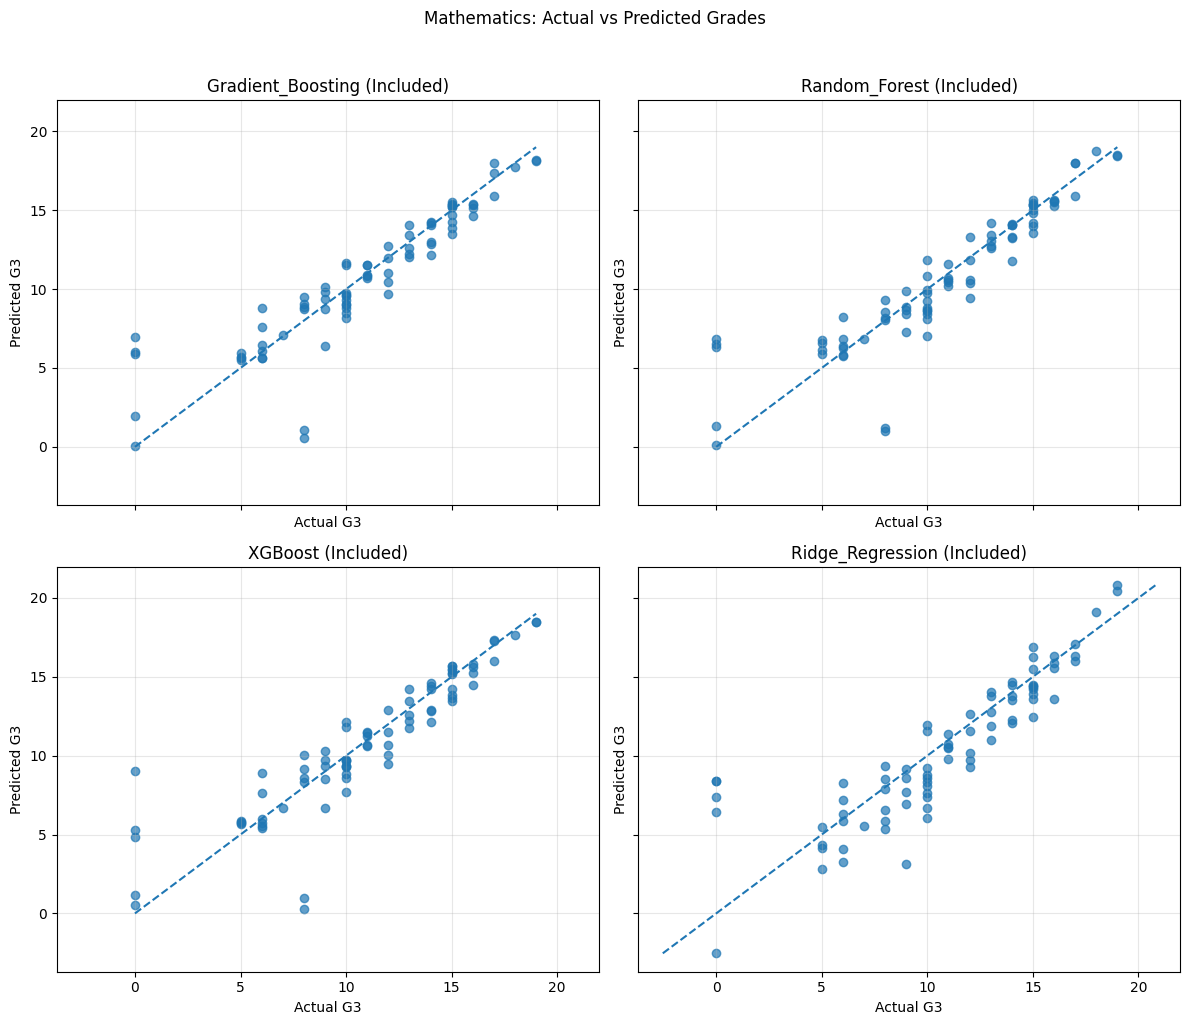

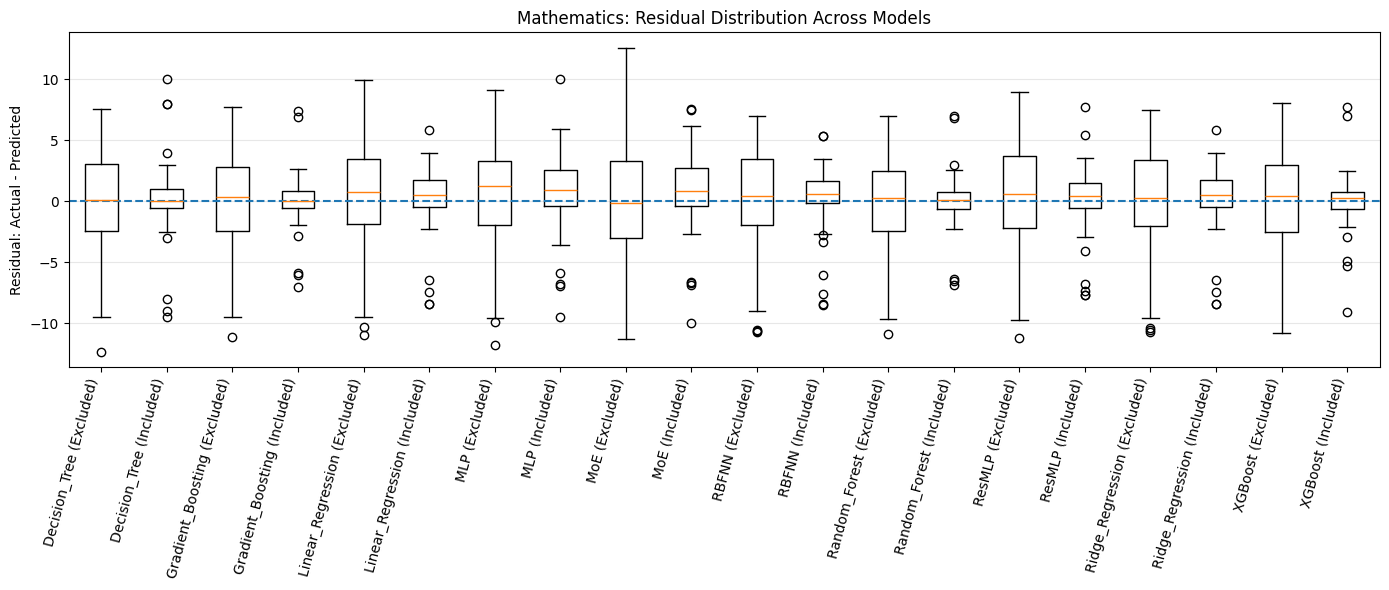

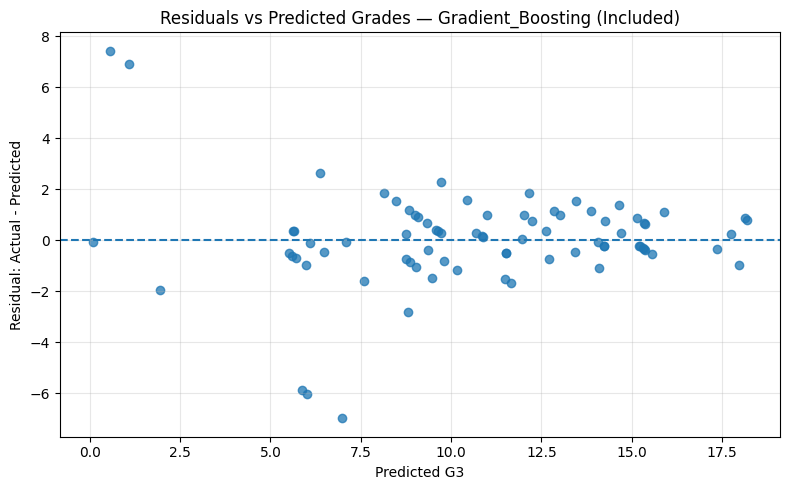

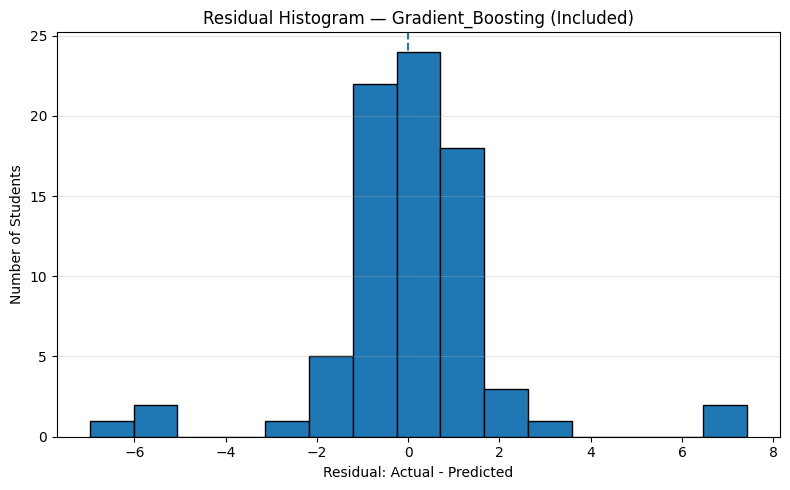


Error by actual grade range:


,Model,Actual grade range,Students,MAE,RMSE
0,Gradient_Boosting (Included),0–5,9,2.630,3.730
1,XGBoost (Included),0–5,9,2.663,3.911
2,Random_Forest (Included),0–5,9,2.946,3.934
3,ResMLP (Included),0–5,9,3.853,4.999
4,RBFNN (Included),0–5,9,3.918,5.230
...,...,...,...,...,...
75,XGBoost (Excluded),>5–10,29,2.647,3.192
76,Decision_Tree (Excluded),>5–10,29,2.638,3.307
77,MLP (Included),>5–10,29,2.643,3.392
78,Linear_Regression (Excluded),>5–10,29,3.002,3.927


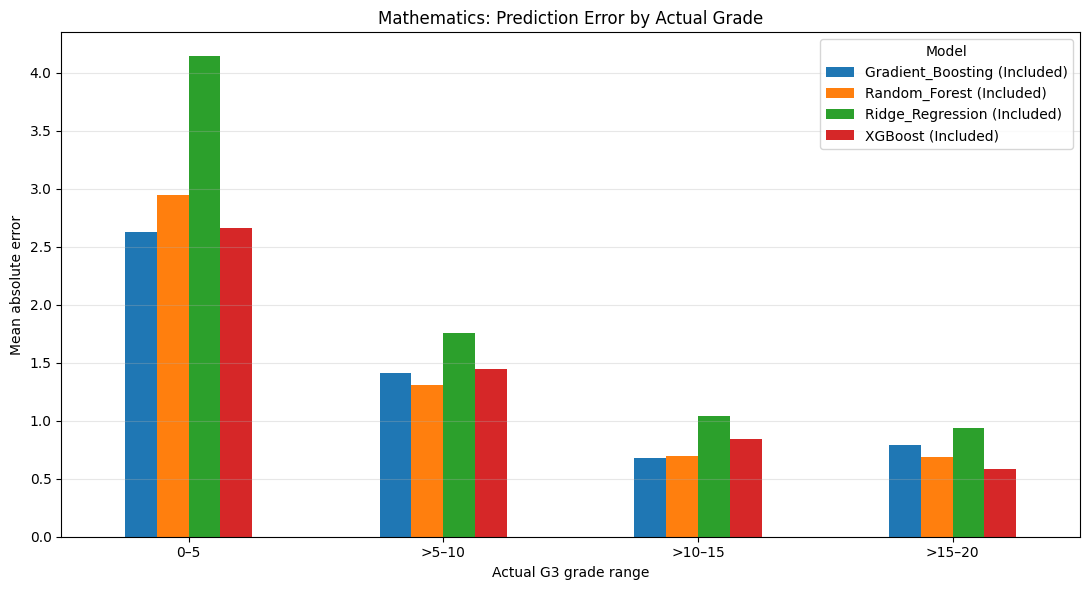


Ten largest errors for Gradient_Boosting (Included):


,Actual G3,Predicted G3,Residual,Absolute error
0,8.0,0.573,7.427,7.427
1,0.0,6.977,-6.977,6.977
2,8.0,1.077,6.923,6.923
3,0.0,6.006,-6.006,6.006
4,0.0,5.885,-5.885,5.885
5,6.0,8.815,-2.815,2.815
6,9.0,6.370,2.630,2.630
7,12.0,9.709,2.291,2.291
8,0.0,1.941,-1.941,1.941
9,10.0,8.146,1.854,1.854


In [31]:

# ============================================================
# 4. ANALYSE PREDICTION ERRORS — MATHEMATICS
# Uses saved predictions only; no model retraining
# Includes models with and without G1/G2
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. LOCATE RESULTS FOLDER
# ------------------------------------------------------------

cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

RESULTS_DIR = ROOT / "data" / "Results"

if not RESULTS_DIR.exists():
    raise FileNotFoundError(f"Results folder not found: {RESULTS_DIR}")

# ------------------------------------------------------------
# 2. LOAD ALL MATHEMATICS PREDICTION FILES
# ------------------------------------------------------------

files = sorted(
    set(RESULTS_DIR.glob("*_Mat.xlsx")) |
    set(RESULTS_DIR.glob("*_Mat_g1g2.xlsx"))
)

model_data = {}
skipped = []

for file in files:
    try:
        df = pd.read_excel(file)

        required = {"G3_actual", "G3_predicted"}
        if not required.issubset(df.columns):
            skipped.append((file.name, "Required columns missing"))
            continue

        actual = pd.to_numeric(
            df["G3_actual"], errors="coerce"
        ).to_numpy(dtype=float)

        predicted = pd.to_numeric(
            df["G3_predicted"], errors="coerce"
        ).to_numpy(dtype=float)

        valid = np.isfinite(actual) & np.isfinite(predicted)
        actual = actual[valid]
        predicted = predicted[valid]

        if len(actual) == 0:
            skipped.append((file.name, "No valid predictions"))
            continue

        # Check that all files have the same actual grades in
        # the same order, as expected from the fixed data split.
        if model_data:
            reference_actual = next(iter(model_data.values()))["actual"]

            if (
                len(actual) != len(reference_actual)
                or not np.allclose(actual, reference_actual)
            ):
                skipped.append(
                    (file.name, "Actual grades/order do not match")
                )
                continue

        residuals = actual - predicted
        stem = file.stem

        if stem.endswith("_Mat_g1g2"):
            model_name = stem[:-len("_Mat_g1g2")]
            g1g2_status = "Included"
        elif stem.endswith("_Mat"):
            model_name = stem[:-len("_Mat")]
            g1g2_status = "Excluded"
        else:
            model_name = stem
            g1g2_status = "Unknown"

        label = f"{model_name} ({g1g2_status})"

        model_data[label] = {
            "actual": actual,
            "predicted": predicted,
            "residuals": residuals,
            "file": file.name,
            "model": model_name,
            "G1_G2": g1g2_status
        }

    except Exception as exc:
        skipped.append((file.name, str(exc)))

if not model_data:
    raise ValueError("No valid Mathematics prediction files were found.")

print(f"Loaded {len(model_data)} Mathematics prediction files.")
print(f"Results folder: {RESULTS_DIR}")

if skipped:
    print("\nSkipped files:")
    display(pd.DataFrame(skipped, columns=["File", "Reason"]))

# ------------------------------------------------------------
# 3. SUMMARY OF PREDICTION ERRORS
# ------------------------------------------------------------

summary = []

for label, data in model_data.items():
    actual = data["actual"]
    predicted = data["predicted"]
    residuals = data["residuals"]

    summary.append({
        "Model": label,
        "G1/G2": data["G1_G2"],
        "N": len(actual),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
        "Mean residual": np.mean(residuals),
        "Mean absolute residual": np.mean(np.abs(residuals)),
        "Maximum absolute error": np.max(np.abs(residuals))
    })

summary_df = pd.DataFrame(summary).sort_values("RMSE")

print("\nPrediction-error summary (best RMSE first):")
display(summary_df.round(3).reset_index(drop=True))

# ------------------------------------------------------------
# 4. ACTUAL VS PREDICTED GRADES — FOUR BEST MODELS
# ------------------------------------------------------------

best_labels = summary_df.head(min(4, len(summary_df)))["Model"].tolist()

fig, axes = plt.subplots(
    2, 2, figsize=(12, 10), sharex=True, sharey=True
)
axes = axes.flatten()

for ax, label in zip(axes, best_labels):
    data = model_data[label]
    actual = data["actual"]
    predicted = data["predicted"]

    ax.scatter(actual, predicted, alpha=0.7)
    low = min(actual.min(), predicted.min())
    high = max(actual.max(), predicted.max())
    ax.plot([low, high], [low, high], linestyle="--")

    ax.set_title(label)
    ax.set_xlabel("Actual G3")
    ax.set_ylabel("Predicted G3")
    ax.grid(True, alpha=0.3)

for ax in axes[len(best_labels):]:
    ax.set_visible(False)

fig.suptitle("Mathematics: Actual vs Predicted Grades", y=1.02)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. RESIDUAL DISTRIBUTIONS — ALL MODELS
# ------------------------------------------------------------

residual_labels = list(model_data.keys())
residual_values = [
    model_data[label]["residuals"] for label in residual_labels
]

fig, ax = plt.subplots(figsize=(14, 6))
ax.boxplot(residual_values, showfliers=True)
ax.axhline(0, linestyle="--")
ax.set_xticks(range(1, len(residual_labels) + 1))
ax.set_xticklabels(residual_labels, rotation=75, ha="right")
ax.set_ylabel("Residual: Actual - Predicted")
ax.set_title("Mathematics: Residual Distribution Across Models")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. RESIDUALS VS PREDICTED GRADES — BEST MODEL
# ------------------------------------------------------------

best_label = summary_df.iloc[0]["Model"]
best_data = model_data[best_label]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    best_data["predicted"],
    best_data["residuals"],
    alpha=0.75
)
ax.axhline(0, linestyle="--")
ax.set_xlabel("Predicted G3")
ax.set_ylabel("Residual: Actual - Predicted")
ax.set_title(f"Residuals vs Predicted Grades — {best_label}")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. RESIDUAL HISTOGRAM — BEST MODEL
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(best_data["residuals"], bins=15, edgecolor="black")
ax.axvline(0, linestyle="--")
ax.set_xlabel("Residual: Actual - Predicted")
ax.set_ylabel("Number of Students")
ax.set_title(f"Residual Histogram — {best_label}")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. ERROR BY ACTUAL GRADE RANGE
# ------------------------------------------------------------

# Grade bands make it easier to see whether models struggle
# more with low, middle, or high actual grades.
grade_bins = [-0.01, 5, 10, 15, 20]
grade_labels = ["0–5", ">5–10", ">10–15", ">15–20"]

grade_error_rows = []

for label, data in model_data.items():
    temp = pd.DataFrame({
        "Actual": data["actual"],
        "Predicted": data["predicted"]
    })

    temp["Absolute error"] = np.abs(
        temp["Actual"] - temp["Predicted"]
    )
    temp["Grade range"] = pd.cut(
        temp["Actual"],
        bins=grade_bins,
        labels=grade_labels,
        include_lowest=True,
        right=True
    )

    for grade_range, group in temp.groupby(
        "Grade range", observed=False
    ):
        if len(group) == 0:
            continue

        grade_error_rows.append({
            "Model": label,
            "Actual grade range": str(grade_range),
            "Students": len(group),
            "MAE": group["Absolute error"].mean(),
            "RMSE": np.sqrt(
                np.mean(
                    (group["Actual"] - group["Predicted"]) ** 2
                )
            )
        })

grade_error_df = pd.DataFrame(grade_error_rows)

print("\nError by actual grade range:")
display(
    grade_error_df
    .sort_values(["Actual grade range", "RMSE"])
    .round(3)
    .reset_index(drop=True)
)

# Plot MAE by grade range for the four best overall models.
top_models = summary_df.head(min(4, len(summary_df)))["Model"].tolist()

plot_data = grade_error_df[
    grade_error_df["Model"].isin(top_models)
]

if not plot_data.empty:
    pivot = plot_data.pivot(
        index="Actual grade range",
        columns="Model",
        values="MAE"
    ).reindex(grade_labels)

    ax = pivot.plot(
        kind="bar",
        figsize=(11, 6)
    )
    ax.set_xlabel("Actual G3 grade range")
    ax.set_ylabel("Mean absolute error")
    ax.set_title("Mathematics: Prediction Error by Actual Grade")
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 9. LARGEST ERRORS FOR THE BEST MODEL
# ------------------------------------------------------------

largest_errors = pd.DataFrame({
    "Actual G3": best_data["actual"],
    "Predicted G3": best_data["predicted"],
    "Residual": best_data["residuals"],
    "Absolute error": np.abs(best_data["residuals"])
}).sort_values("Absolute error", ascending=False)

print(f"\nTen largest errors for {best_label}:")
display(largest_errors.head(10).round(3).reset_index(drop=True))


MATHEMATICS: EFFECT OF INCLUDING G1 AND G2


,Model,RMSE without G1/G2,RMSE with G1/G2,RMSE improvement,RMSE improvement (%),MAE without G1/G2,MAE with G1/G2,MAE improvement,R2 without G1/G2,R2 with G1/G2,R2 improvement,Test students
0,XGBoost,4.0443,2.0357,2.0087,49.6663,3.3185,1.2391,2.0794,0.2023,0.7979,0.5956,79
1,Gradient_Boosting,3.9379,1.9446,1.9933,50.6186,3.2060,1.1827,2.0232,0.2437,0.8156,0.5718,79
2,Ridge_Regression,4.2656,2.3764,1.8892,44.2899,3.4424,1.6452,1.7972,0.1126,0.7246,0.6120,79
3,Linear_Regression,4.1957,2.3784,1.8173,43.3139,3.3953,1.6467,1.7486,0.1415,0.7241,0.5826,79
4,Random_Forest,3.7576,1.9629,1.7948,47.7630,3.0153,1.1763,1.8390,0.3114,0.8121,0.5007,79
5,ResMLP,4.2901,2.5115,1.7786,41.4577,3.4738,1.7408,1.7330,0.1024,0.6924,0.5900,79
6,RBFNN,4.1647,2.4095,1.7552,42.1442,3.3595,1.6063,1.7532,0.1541,0.7169,0.5627,79
7,Decision_Tree,4.3943,2.6694,1.7249,39.2524,3.5409,1.3966,2.1443,0.0583,0.6525,0.5942,79
8,MoE,4.7193,3.0655,1.6538,35.0431,3.7391,2.2642,1.4749,-0.0862,0.5417,0.6279,79
9,MLP,4.2921,3.0596,1.2326,28.7167,3.4336,2.2301,1.2035,0.1016,0.5435,0.4419,79



Summary:
Model pairs compared: 10
Models with lower RMSE after including G1/G2: 10
Models with lower MAE after including G1/G2: 10
Models with higher R² after including G1/G2: 10

Average RMSE improvement: 1.7648
Average percentage RMSE improvement: 42.23 %


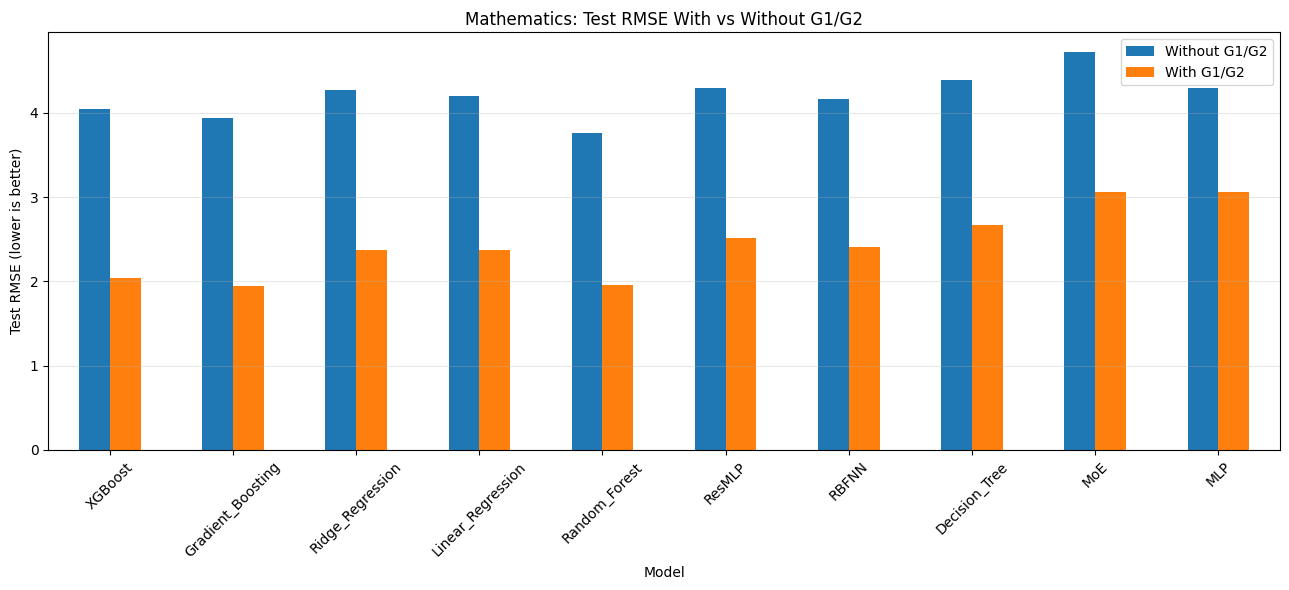

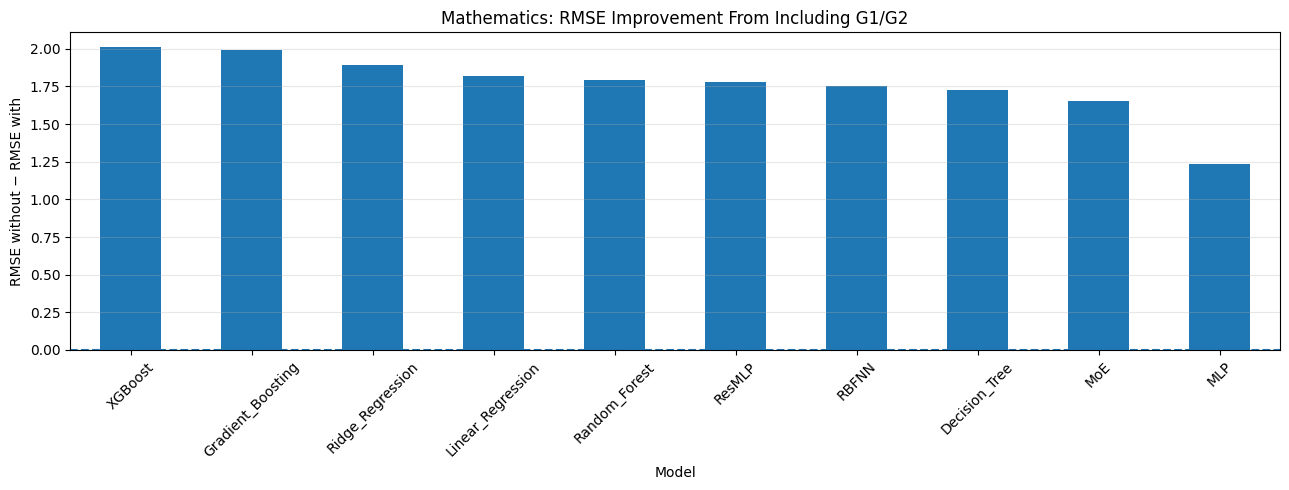

In [32]:

# ============================================================
# STEP 5: EFFECT OF INCLUDING G1 AND G2 — MATHEMATICS
# Uses saved prediction files; no model retraining
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Locate project folder
cwd = Path.cwd()

if cwd.name == "codes":
    ROOT = cwd.parent
elif (cwd / "data" / "student_data.xlsx").exists():
    ROOT = cwd
elif (cwd / "IDC409_Project" / "data" / "student_data.xlsx").exists():
    ROOT = cwd / "IDC409_Project"
else:
    ROOT = Path.home() / "Documents" / "IDC409_Project"

RESULTS_DIR = ROOT / "data" / "Results"

if not RESULTS_DIR.exists():
    raise FileNotFoundError(f"Results folder not found: {RESULTS_DIR}")

# Load a saved prediction file and validate its columns
def load_predictions(path):
    if not path.exists():
        raise FileNotFoundError(f"Missing prediction file: {path.name}")

    df = pd.read_excel(path)
    required = {"G3_actual", "G3_predicted"}

    if not required.issubset(df.columns):
        raise ValueError(f"{path.name} must contain {required}")

    df = df[["G3_actual", "G3_predicted"]].apply(
        pd.to_numeric, errors="coerce"
    ).dropna()

    return df.reset_index(drop=True)

# Model filename stems, excluding the subject suffix
models = [
    "Linear_Regression",
    "Ridge_Regression",
    "Decision_Tree",
    "Random_Forest",
    "Gradient_Boosting",
    "XGBoost",
    "MLP",
    "MoE",
    "RBFNN",
    "ResMLP",
]

results = []

for model_name in models:
    without_file = RESULTS_DIR / f"{model_name}_Mat.xlsx"
    with_file = RESULTS_DIR / f"{model_name}_Mat_g1g2.xlsx"

    try:
        without = load_predictions(without_file)
        with_g1g2 = load_predictions(with_file)
    except FileNotFoundError as exc:
        print(f"Skipping {model_name}: {exc}")
        continue

    # The files should refer to the same held-out students in the same order.
    if len(without) != len(with_g1g2):
        print(f"Skipping {model_name}: different test-set sizes.")
        continue

    if not np.allclose(
        without["G3_actual"].to_numpy(),
        with_g1g2["G3_actual"].to_numpy()
    ):
        print(f"Skipping {model_name}: actual grades do not align.")
        continue

    y = without["G3_actual"].to_numpy()
    pred_without = without["G3_predicted"].to_numpy()
    pred_with = with_g1g2["G3_predicted"].to_numpy()

    rmse_without = np.sqrt(mean_squared_error(y, pred_without))
    rmse_with = np.sqrt(mean_squared_error(y, pred_with))
    mae_without = mean_absolute_error(y, pred_without)
    mae_with = mean_absolute_error(y, pred_with)
    r2_without = r2_score(y, pred_without)
    r2_with = r2_score(y, pred_with)

    results.append({
        "Model": model_name,
        "RMSE without G1/G2": rmse_without,
        "RMSE with G1/G2": rmse_with,
        "RMSE improvement": rmse_without - rmse_with,
        "RMSE improvement (%)": (
            100 * (rmse_without - rmse_with) / rmse_without
            if rmse_without != 0 else np.nan
        ),
        "MAE without G1/G2": mae_without,
        "MAE with G1/G2": mae_with,
        "MAE improvement": mae_without - mae_with,
        "R2 without G1/G2": r2_without,
        "R2 with G1/G2": r2_with,
        "R2 improvement": r2_with - r2_without,
        "Test students": len(y),
    })

comparison = pd.DataFrame(results)

if comparison.empty:
    raise ValueError(
        "No valid model pairs were found. Check the prediction filenames."
    )

comparison = comparison.sort_values(
    "RMSE improvement", ascending=False
).reset_index(drop=True)

print("MATHEMATICS: EFFECT OF INCLUDING G1 AND G2")
display(comparison.round(4))

print("\nSummary:")
print(f"Model pairs compared: {len(comparison)}")
print(
    "Models with lower RMSE after including G1/G2:",
    int((comparison["RMSE improvement"] > 0).sum())
)
print(
    "Models with lower MAE after including G1/G2:",
    int((comparison["MAE improvement"] > 0).sum())
)
print(
    "Models with higher R² after including G1/G2:",
    int((comparison["R2 improvement"] > 0).sum())
)

print(
    "\nAverage RMSE improvement:",
    round(comparison["RMSE improvement"].mean(), 4)
)
print(
    "Average percentage RMSE improvement:",
    round(comparison["RMSE improvement (%)"].mean(), 2), "%"
)

# Plot RMSE before vs after including G1/G2
plot_df = comparison.set_index("Model")[
    ["RMSE without G1/G2", "RMSE with G1/G2"]
]

ax = plot_df.plot(kind="bar", figsize=(13, 6))
ax.set_title("Mathematics: Test RMSE With vs Without G1/G2")
ax.set_ylabel("Test RMSE (lower is better)")
ax.set_xlabel("Model")
ax.grid(axis="y", alpha=0.3)
ax.legend(["Without G1/G2", "With G1/G2"])
ax.tick_params(axis="x", rotation=45)
ax.figure.tight_layout()
import matplotlib.pyplot as plt
plt.show()

# Plot absolute RMSE improvement
ax = comparison.set_index("Model")["RMSE improvement"].plot(
    kind="bar", figsize=(13, 5)
)
ax.axhline(0, linestyle="--")
ax.set_title("Mathematics: RMSE Improvement From Including G1/G2")
ax.set_ylabel("RMSE without − RMSE with")
ax.set_xlabel("Model")
ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="x", rotation=45)
ax.figure.tight_layout()
plt.show()
